In [389]:
%pip install catboost

In [390]:
#import libraries

import pandas as pd
import zipfile
import requests
from io import BytesIO
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy.sparse import csr_matrix
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV
from sklearn.feature_selection import RFECV
from sklearn.feature_selection import RFE
from sklearn.model_selection import KFold, cross_validate
import itertools




In [391]:
%pip install pyDOE2

In [392]:
!pip install catboost

In [393]:

url = "https://www.kaggle.com/api/v1/datasets/download/rafsunahmad/plane-price-prediction"

response = requests.get(url)

with zipfile.ZipFile(BytesIO(response.content)) as z:
    df = pd.read_csv(
        z.open("Plane Price.csv")
    )

df.head(20)

,Model Name,Engine Type,HP or lbs thr ea engine,Max speed Knots,Rcmnd cruise Knots,Stall Knots dirty,Fuel gal/lbs,All eng rate of climb,Eng out rate of climb,Takeoff over 50ft,Landing over 50ft,Empty weight lbs,Length ft/in,Wing span ft/in,Range N.M.,Price
0,100 Darter (S.L. Industries),Piston,145,104,91.0,46.0,36,450,900.0,1300.0,"2,050","1,180",25/3,37/5,370,1300000.0
1,7 CCM Champ,Piston,85,89,83.0,44.0,15,600,720.0,800.0,"1,350",820,20/7,36/1,190,1230000.0
2,100 Darter (S.L. Industries),Piston,90,90,78.0,37.0,19,650,475.0,850.0,"1,300",810,21/5,35/0,210,1600000.0
3,7 AC Champ,Piston,85,88,78.0,37.0,19,620,500.0,850.0,"1,300",800,21/5,35/0,210,1300000.0
4,100 Darter (S.L. Industries),Piston,65,83,74.0,33.0,14,370,632.0,885.0,"1,220",740,21/5,35/0,175,1250000.0
5,PA-60-700P Aerostar (preliminary),Piston,65,78,72.0,33.0,15,360,583.0,880.0,"1,250",786,20/4,36/1,180,1100000.0
6,PA-601P pressurized Aerostar ('77 service ceil...,Piston,350,264,230.0,80.0,165,"1,820",3080.0,2100.0,"6,315","4,275",34/10,36/8,868,2500000.0
7,100 Darter (S.L. Industries),Piston,290,262,247.0,77.0,165,"1,755",2250.0,2076.0,"6,000","4,125",34/9,36/7,"1,020",2800000.0
8,"PA-601, 601A, turbochg Aerostar",Piston,290,257,235.0,77.0,165,"1,460",2490.0,2030.0,"6,000","4,056",34/10,36/8,"1,101",2500000.0
9,100 Darter (S.L. Industries),Piston,290,257,237.0,77.0,165,"1,460",2490.0,2030.0,"6,000","3,958",34/10,36/8,"1,174",3000000.0


In [394]:
df.columns

Index(['Model Name', 'Engine Type', 'HP or lbs thr ea engine',
       'Max speed Knots', 'Rcmnd cruise Knots', 'Stall Knots dirty',
       'Fuel gal/lbs', 'All eng rate of climb', 'Eng out rate of climb',
       'Takeoff over 50ft', 'Landing over 50ft', 'Empty weight lbs',
       'Length ft/in', 'Wing span ft/in', 'Range N.M.', 'Price'],
      dtype='object')

In [395]:
df.isna().sum()

,0
Model Name,0
Engine Type,0
HP or lbs thr ea engine,0
Max speed Knots,20
Rcmnd cruise Knots,10
Stall Knots dirty,15
Fuel gal/lbs,0
All eng rate of climb,4
Eng out rate of climb,26
Takeoff over 50ft,25


In [396]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 517 entries, 0 to 516
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Model Name               517 non-null    object 
 1   Engine Type              517 non-null    object 
 2   HP or lbs thr ea engine  517 non-null    object 
 3   Max speed Knots          497 non-null    object 
 4   Rcmnd cruise Knots       507 non-null    float64
 5   Stall Knots dirty        502 non-null    float64
 6   Fuel gal/lbs             517 non-null    int64  
 7   All eng rate of climb    513 non-null    object 
 8   Eng out rate of climb    491 non-null    float64
 9   Takeoff over 50ft        492 non-null    float64
 10  Landing over 50ft        517 non-null    object 
 11  Empty weight lbs         516 non-null    object 
 12  Length ft/in             517 non-null    object 
 13  Wing span ft/in          517 non-null    object 
 14  Range N.M.               4

In [397]:
df_clean = df.dropna()

In [398]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 421 entries, 0 to 516
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Model Name               421 non-null    object 
 1   Engine Type              421 non-null    object 
 2   HP or lbs thr ea engine  421 non-null    object 
 3   Max speed Knots          421 non-null    object 
 4   Rcmnd cruise Knots       421 non-null    float64
 5   Stall Knots dirty        421 non-null    float64
 6   Fuel gal/lbs             421 non-null    int64  
 7   All eng rate of climb    421 non-null    object 
 8   Eng out rate of climb    421 non-null    float64
 9   Takeoff over 50ft        421 non-null    float64
 10  Landing over 50ft        421 non-null    object 
 11  Empty weight lbs         421 non-null    object 
 12  Length ft/in             421 non-null    object 
 13  Wing span ft/in          421 non-null    object 
 14  Range N.M.               421 no

the NAN clean up reduced the data size from 517 to 421, 20% data lost

In [399]:
def feet_inches_to_meters(value):
    if pd.isna(value):
        return np.nan

    value = str(value).strip()

    # Accept only the format feet/inches, e.g. 25/3
    if '/' not in value:
        return np.nan

    try:
        feet, inches = value.split('/')

        feet = float(feet)
        inches = float(inches)

        return feet * 0.3048 + inches * 0.0254

    except (ValueError, TypeError):
        return np.nan


# Convert columns
df['Length_m'] = df['Length ft/in'].apply(feet_inches_to_meters)
df['Wing_Span_m'] = df['Wing span ft/in'].apply(feet_inches_to_meters)

#delet ft/in column

df = df.drop(columns=['Length ft/in', 'Wing span ft/in'])

In [400]:
df.isna().sum()

,0
Model Name,0
Engine Type,0
HP or lbs thr ea engine,0
Max speed Knots,20
Rcmnd cruise Knots,10
Stall Knots dirty,15
Fuel gal/lbs,0
All eng rate of climb,4
Eng out rate of climb,26
Takeoff over 50ft,25


In [401]:
df.head()

,Model Name,Engine Type,HP or lbs thr ea engine,Max speed Knots,Rcmnd cruise Knots,Stall Knots dirty,Fuel gal/lbs,All eng rate of climb,Eng out rate of climb,Takeoff over 50ft,Landing over 50ft,Empty weight lbs,Range N.M.,Price,Length_m,Wing_Span_m
0,100 Darter (S.L. Industries),Piston,145,104,91.0,46.0,36,450,900.0,1300.0,"2,050","1,180",370,1300000.0,7.6962,11.4046
1,7 CCM Champ,Piston,85,89,83.0,44.0,15,600,720.0,800.0,"1,350",820,190,1230000.0,6.2738,10.9982
2,100 Darter (S.L. Industries),Piston,90,90,78.0,37.0,19,650,475.0,850.0,"1,300",810,210,1600000.0,6.5278,10.6680
3,7 AC Champ,Piston,85,88,78.0,37.0,19,620,500.0,850.0,"1,300",800,210,1300000.0,6.5278,10.6680
4,100 Darter (S.L. Industries),Piston,65,83,74.0,33.0,14,370,632.0,885.0,"1,220",740,175,1250000.0,6.5278,10.6680


In [402]:
# IDENTIFY NUMERIC OBJECT COLUMNS


for col in df.select_dtypes(include='object').columns:

    converted = pd.to_numeric(
        df[col]
        .astype(str)
        .str.replace(',', '', regex=False)
        .str.strip(),
        errors='coerce'
    )

    percentage = converted.notna().mean() * 100

    print(f"{col}: {percentage:.2f}% numeric")

Model Name: 1.93% numeric
Engine Type: 0.00% numeric
HP or lbs thr ea engine: 99.61% numeric
Max speed Knots: 94.39% numeric
All eng rate of climb: 98.65% numeric
Landing over 50ft: 99.81% numeric
Empty weight lbs: 99.81% numeric
Range N.M.: 96.52% numeric


In [403]:
#transforming obj in float

numeric_cols = [
    'HP or lbs thr ea engine',
    'Max speed Knots',
    'All eng rate of climb',
    'Landing over 50ft',
    'Empty weight lbs',
    'Range N.M.'
]

for col in numeric_cols:
    df[col] = (
        df[col]
        .astype(str)
        .str.replace(',', '', regex=False)
        .str.strip()
    )

    df[col] = pd.to_numeric(
        df[col],
        errors='coerce'
    )

In [404]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 517 entries, 0 to 516
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Model Name               517 non-null    object 
 1   Engine Type              517 non-null    object 
 2   HP or lbs thr ea engine  515 non-null    float64
 3   Max speed Knots          488 non-null    float64
 4   Rcmnd cruise Knots       507 non-null    float64
 5   Stall Knots dirty        502 non-null    float64
 6   Fuel gal/lbs             517 non-null    int64  
 7   All eng rate of climb    510 non-null    float64
 8   Eng out rate of climb    491 non-null    float64
 9   Takeoff over 50ft        492 non-null    float64
 10  Landing over 50ft        516 non-null    float64
 11  Empty weight lbs         516 non-null    float64
 12  Range N.M.               499 non-null    float64
 13  Price                    507 non-null    float64
 14  Length_m                 5

In [405]:
# MISSING VALUES ANALYSIS

missing_analysis = pd.DataFrame({
    'Missing': df.isna().sum(),
    'Missing_%': df.isna().mean() * 100,
    'Non_Missing': df.notna().sum(),
    'Non_Missing_%': df.notna().mean() * 100
})

missing_analysis = missing_analysis.sort_values(
    by='Missing_%',
    ascending=False
)

missing_analysis

,Missing,Missing_%,Non_Missing,Non_Missing_%
Max speed Knots,29,5.609284,488,94.390716
Eng out rate of climb,26,5.029014,491,94.970986
Takeoff over 50ft,25,4.835590,492,95.164410
Range N.M.,18,3.481625,499,96.518375
Stall Knots dirty,15,2.901354,502,97.098646
Price,10,1.934236,507,98.065764
Rcmnd cruise Knots,10,1.934236,507,98.065764
Wing_Span_m,8,1.547389,509,98.452611
All eng rate of climb,7,1.353965,510,98.646035
Length_m,4,0.773694,513,99.226306


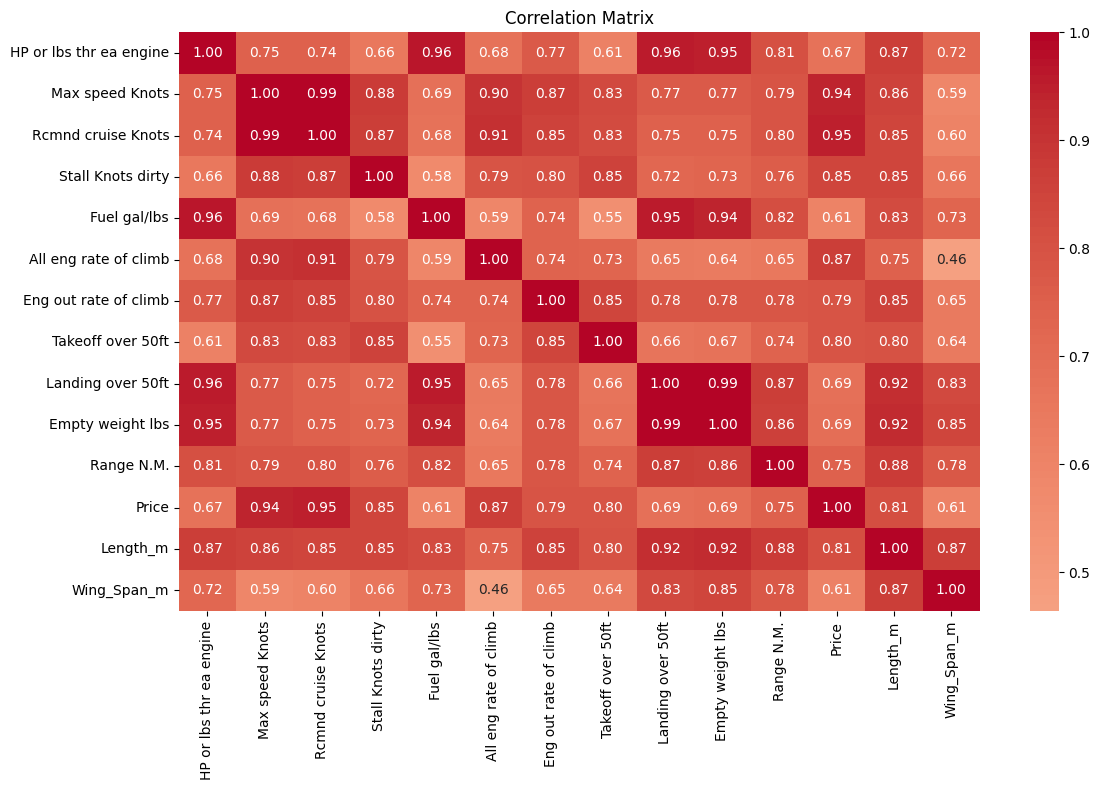

In [406]:
plt.figure(figsize=(12, 8))

corr = df.select_dtypes(include='number').corr()

sns.heatmap(
    corr,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0
)

plt.title('Correlation Matrix')
plt.tight_layout()
plt.show()

In [407]:
#spliting data

df_train, df_test = train_test_split(
    df,
    test_size=0.20,
    random_state=42
)

In [408]:
df=df_train

In [409]:
#Spliting DF in test and trains set

df_train, df_test = train_test_split(
    df,
    test_size=0.20,
    random_state=1
)

In [410]:
df = df_train.copy()

the correlation maop showed the possibility to imput values on NAN row by ML models.


In [411]:

# ============================================================
# 1. BASE DATASET
# ============================================================

df_data_treat_xgb = df.copy()
df_data_treat_xgb = df_data_treat_xgb.drop(columns=['Price'])

# ============================================================
# 2. IDENTIFY NUMERIC AND CATEGORICAL COLUMNS
# ============================================================

numeric_cols = df_data_treat_xgb.select_dtypes(
    include=np.number
).columns.tolist()

categorical_cols = df_data_treat_xgb.select_dtypes(
    include='object'
).columns.tolist()


# ============================================================
# 3. STORE IMPUTATION RESULTS
# ============================================================

imputation_results_xgb = []


# ============================================================
# 4. COLUMN-BY-COLUMN IMPUTATION USING XGBOOST
# ============================================================

for target_col in numeric_cols:

    # Number of missing values
    n_missing = df_data_treat_xgb[target_col].isna().sum()

    # Skip columns without missing values
    if n_missing == 0:
        continue

    print("\n" + "=" * 70)
    print(f"Imputing column: {target_col}")
    print(f"Missing values: {n_missing}")

    # --------------------------------------------------------
    # Features = all other numeric columns
    # --------------------------------------------------------

    feature_cols = [
        col for col in numeric_cols
        if col != target_col
    ]

    # --------------------------------------------------------
    # Separate observed and missing values
    # --------------------------------------------------------

    train_mask = df_data_treat_xgb[target_col].notna()
    missing_mask = df_data_treat_xgb[target_col].isna()

    X = df_data_treat_xgb.loc[
        train_mask, feature_cols
    ].copy()

    y = df_data_treat_xgb.loc[
        train_mask, target_col
    ].copy()

    X_missing = df_data_treat_xgb.loc[
        missing_mask, feature_cols
    ].copy()

    # --------------------------------------------------------
    # Fill missing feature values with the median
    # --------------------------------------------------------

    medians = X.median()

    X = X.fillna(medians)
    X_missing = X_missing.fillna(medians)

    # --------------------------------------------------------
    # Train / validation split
    # --------------------------------------------------------

    X_train, X_valid, y_train, y_valid = train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=42
    )

    # --------------------------------------------------------
    # XGBoost model
    # --------------------------------------------------------

    model = XGBRegressor(
        n_estimators=100,
        max_depth=3,
        learning_rate=0.05,
        random_state=42
    )

    # Train model
    model.fit(X_train, y_train)

    # --------------------------------------------------------
    # Validation predictions
    # --------------------------------------------------------

    y_pred = model.predict(X_valid)

    # --------------------------------------------------------
    # Evaluation metrics
    # --------------------------------------------------------

    mae = mean_absolute_error(y_valid, y_pred)

    rmse = np.sqrt(
        mean_squared_error(y_valid, y_pred)
    )

    r2 = r2_score(y_valid, y_pred)

    # --------------------------------------------------------
    # Train final model using all available values
    # --------------------------------------------------------

    final_model = XGBRegressor(
        n_estimators=100,
        max_depth=3,
        learning_rate=0.05,
        random_state=42
    )

    final_model.fit(X, y)

    # --------------------------------------------------------
    # Predict missing values
    # --------------------------------------------------------

    predictions = final_model.predict(X_missing)

    # --------------------------------------------------------
    # Replace only missing values
    # --------------------------------------------------------

    df_data_treat_xgb.loc[
        missing_mask,
        target_col
    ] = predictions

    # --------------------------------------------------------
    # Store metrics in dictionary
    # --------------------------------------------------------

    imputation_results_xgb.append({
        "Column": target_col,
        "Imputation_Method": "XGBoost",
        "Missing_Values": n_missing,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

    # --------------------------------------------------------
    # Display metrics
    # --------------------------------------------------------

    print(f"Imputed values: {len(predictions)}")
    print(f"MAE  : {mae:.4f}")
    print(f"RMSE : {rmse:.4f}")
    print(f"R²   : {r2:.4f}")


# ============================================================
# 5. CONVERT RESULTS TO DATAFRAME
# ============================================================

df_xgb_metrics = pd.DataFrame(
    imputation_results_xgb
)


# ============================================================
# 6. DISPLAY IMPUTATION PERFORMANCE
# ============================================================

print("\n" + "=" * 70)
print("XGBOOST IMPUTATION PERFORMANCE")
print("=" * 70)

print(
    df_xgb_metrics.to_string(index=False)
)


# ============================================================
# 7. CHECK REMAINING MISSING VALUES
# ============================================================

print("\nMissing values after XGBoost imputation:")

print(
    df_data_treat_xgb.isna().sum()
)



Imputing column: HP or lbs thr ea engine
Missing values: 2
Imputed values: 2
MAE  : 78.0378
RMSE : 130.6226
R²   : 0.9702

Imputing column: Max speed Knots
Missing values: 20
Imputed values: 20
MAE  : 7.3431
RMSE : 10.9187
R²   : 0.9914

Imputing column: Rcmnd cruise Knots
Missing values: 7
Imputed values: 7
MAE  : 8.2146
RMSE : 11.5532
R²   : 0.9841

Imputing column: Stall Knots dirty
Missing values: 11
Imputed values: 11
MAE  : 4.0409
RMSE : 5.7868
R²   : 0.8869

Imputing column: All eng rate of climb
Missing values: 3
Imputed values: 3
MAE  : 140.3019
RMSE : 203.0213
R²   : 0.9608

Imputing column: Eng out rate of climb
Missing values: 17
Imputed values: 17
MAE  : 221.9357
RMSE : 277.9643
R²   : 0.9254

Imputing column: Takeoff over 50ft
Missing values: 17
Imputed values: 17
MAE  : 161.7216
RMSE : 243.6204
R²   : 0.8454

Imputing column: Landing over 50ft
Missing values: 1
Imputed values: 1
MAE  : 329.7915
RMSE : 556.9288
R²   : 0.9915

Imputing column: Range N.M.
Missing values: 9

In [412]:
# ============================================================
# 1. BASE DATASET
# ============================================================

df_data_treat_reg = df.copy()
df_data_treat_reg = df_data_treat_reg.drop(columns=['Price'])

# ============================================================
# 2. IDENTIFY NUMERIC AND CATEGORICAL COLUMNS
# ============================================================

numeric_cols = df_data_treat_reg.select_dtypes(
    include=np.number
).columns.tolist()

categorical_cols = df_data_treat_reg.select_dtypes(
    include='object'
).columns.tolist()


# ============================================================
# 3. STORE IMPUTATION RESULTS
# ============================================================

imputation_results_reg = []


# ============================================================
# 4. COLUMN-BY-COLUMN IMPUTATION USING LINEAR REGRESSION
# ============================================================

for target_col in numeric_cols:

    # Number of missing values
    n_missing = df_data_treat_reg[target_col].isna().sum()

    # Skip columns without missing values
    if n_missing == 0:
        continue

    print("\n" + "=" * 70)
    print(f"Imputing column: {target_col}")
    print(f"Missing values: {n_missing}")

    # --------------------------------------------------------
    # Features = all other numeric columns
    # --------------------------------------------------------

    feature_cols = [
        col for col in numeric_cols
        if col != target_col
    ]

    # --------------------------------------------------------
    # Separate observed and missing values
    # --------------------------------------------------------

    train_mask = df_data_treat_reg[target_col].notna()
    missing_mask = df_data_treat_reg[target_col].isna()

    X = df_data_treat_reg.loc[
        train_mask, feature_cols
    ].copy()

    y = df_data_treat_reg.loc[
        train_mask, target_col
    ].copy()

    X_missing = df_data_treat_reg.loc[
        missing_mask, feature_cols
    ].copy()

    # --------------------------------------------------------
    # Fill missing feature values with the median
    # --------------------------------------------------------

    medians = X.median()

    X = X.fillna(medians)
    X_missing = X_missing.fillna(medians)

    # --------------------------------------------------------
    # Train / validation split
    # --------------------------------------------------------

    X_train, X_valid, y_train, y_valid = train_test_split(
        X,
        y,
        test_size=0.20,
        random_state=42
    )

    # --------------------------------------------------------
    # Linear Regression model
    # --------------------------------------------------------

    model = LinearRegression()

    # Train model
    model.fit(X_train, y_train)

    # --------------------------------------------------------
    # Validation predictions
    # --------------------------------------------------------

    y_pred = model.predict(X_valid)

    # --------------------------------------------------------
    # Evaluation metrics
    # --------------------------------------------------------

    mae = mean_absolute_error(y_valid, y_pred)

    rmse = np.sqrt(
        mean_squared_error(y_valid, y_pred)
    )

    r2 = r2_score(y_valid, y_pred)

    # --------------------------------------------------------
    # Train final model using all available values
    # --------------------------------------------------------

    final_model = LinearRegression()

    final_model.fit(X, y)

    # --------------------------------------------------------
    # Predict missing values
    # --------------------------------------------------------

    predictions = final_model.predict(X_missing)

    # --------------------------------------------------------
    # Replace only missing values
    # --------------------------------------------------------

    df_data_treat_reg.loc[
        missing_mask,
        target_col
    ] = predictions

    # --------------------------------------------------------
    # Store metrics in dictionary
    # --------------------------------------------------------

    imputation_results_reg.append({
        "Column": target_col,
        "Imputation_Method": "Linear Regression",
        "Missing_Values": n_missing,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

    # --------------------------------------------------------
    # Display metrics
    # --------------------------------------------------------

    print(f"Imputed values: {len(predictions)}")
    print(f"MAE  : {mae:.4f}")
    print(f"RMSE : {rmse:.4f}")
    print(f"R²   : {r2:.4f}")


# ============================================================
# 5. CONVERT RESULTS TO DATAFRAME
# ============================================================

df_reg_metrics = pd.DataFrame(
    imputation_results_reg
)


# ============================================================
# 6. DISPLAY IMPUTATION PERFORMANCE
# ============================================================

print("\n" + "=" * 70)
print("LINEAR REGRESSION IMPUTATION PERFORMANCE")
print("=" * 70)

print(
    df_reg_metrics.to_string(index=False)
)


# ============================================================
# 7. CHECK REMAINING MISSING VALUES
# ============================================================

print("\nMissing values after Linear Regression imputation:")

print(
    df_data_treat_reg.isna().sum()
)



Imputing column: HP or lbs thr ea engine
Missing values: 2
Imputed values: 2
MAE  : 150.4469
RMSE : 248.2046
R²   : 0.8922

Imputing column: Max speed Knots
Missing values: 20
Imputed values: 20
MAE  : 12.0578
RMSE : 17.3720
R²   : 0.9782

Imputing column: Rcmnd cruise Knots
Missing values: 7
Imputed values: 7
MAE  : 8.0185
RMSE : 11.9572
R²   : 0.9829

Imputing column: Stall Knots dirty
Missing values: 11
Imputed values: 11
MAE  : 4.4525
RMSE : 6.3585
R²   : 0.8634

Imputing column: All eng rate of climb
Missing values: 3
Imputed values: 3
MAE  : 273.1143
RMSE : 356.0531
R²   : 0.8796

Imputing column: Eng out rate of climb
Missing values: 17
Imputed values: 17
MAE  : 296.3397
RMSE : 384.1644
R²   : 0.8574

Imputing column: Takeoff over 50ft
Missing values: 17
Imputed values: 17
MAE  : 203.1631
RMSE : 296.7653
R²   : 0.7705

Imputing column: Landing over 50ft
Missing values: 1
Imputed values: 1
MAE  : 457.9137
RMSE : 638.5066
R²   : 0.9889

Imputing column: Range N.M.
Missing values:

In [413]:
# ============================================================
# 1. BASE DATASET
# ============================================================

df_data_treat_moda = df.copy()
df_data_treat_moda = df_data_treat_moda.drop(columns=['Price'])

# ============================================================
# 2. IDENTIFY NUMERIC AND CATEGORICAL COLUMNS
# ============================================================

numeric_cols = df_data_treat_moda.select_dtypes(
    include=np.number
).columns.tolist()

categorical_cols = df_data_treat_moda.select_dtypes(
    include='object'
).columns.tolist()


# ============================================================
# 3. STORE IMPUTATION RESULTS
# ============================================================

imputation_results_moda = []


# ============================================================
# 4. COLUMN-BY-COLUMN IMPUTATION USING MODE
# ============================================================

for target_col in df_data_treat_moda.columns:

    # Number of missing values
    n_missing = df_data_treat_moda[target_col].isna().sum()

    # Skip columns without missing values
    if n_missing == 0:
        continue

    print("\n" + "=" * 70)
    print(f"Imputing column: {target_col}")
    print(f"Missing values: {n_missing}")

    # --------------------------------------------------------
    # Get available values
    # --------------------------------------------------------

    available_values = df_data_treat_moda.loc[
        df_data_treat_moda[target_col].notna(),
        target_col
    ]

    # --------------------------------------------------------
    # Train / validation split
    # --------------------------------------------------------

    train_values, valid_values = train_test_split(
        available_values,
        test_size=0.20,
        random_state=42
    )

    # --------------------------------------------------------
    # Calculate mode using only training data
    # --------------------------------------------------------

    mode_value = train_values.mode()[0]

    print(f"Mode value: {mode_value}")

    # --------------------------------------------------------
    # Create validation predictions using the mode
    # --------------------------------------------------------

    y_valid = valid_values
    y_pred = np.full(
        len(y_valid),
        mode_value
    )

    # --------------------------------------------------------
    # Evaluation metrics
    # --------------------------------------------------------

    mae = mean_absolute_error(
        y_valid,
        y_pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_valid,
            y_pred
        )
    )

    r2 = r2_score(
        y_valid,
        y_pred
    )

    # --------------------------------------------------------
    # Calculate final mode using all available values
    # --------------------------------------------------------

    final_mode = available_values.mode()[0]

    # --------------------------------------------------------
    # Replace only missing values
    # --------------------------------------------------------

    missing_mask = df_data_treat_moda[target_col].isna()

    df_data_treat_moda.loc[
        missing_mask,
        target_col
    ] = final_mode

    # --------------------------------------------------------
    # Store metrics in dictionary
    # --------------------------------------------------------

    imputation_results_moda.append({
        "Column": target_col,
        "Imputation_Method": "Mode",
        "Missing_Values": n_missing,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

    # --------------------------------------------------------
    # Display metrics
    # --------------------------------------------------------

    print(f"Imputed values: {n_missing}")
    print(f"MAE  : {mae:.4f}")
    print(f"RMSE : {rmse:.4f}")
    print(f"R²   : {r2:.4f}")


# ============================================================
# 5. CONVERT RESULTS TO DATAFRAME
# ============================================================

df_moda_metrics = pd.DataFrame(
    imputation_results_moda
)


# ============================================================
# 6. DISPLAY IMPUTATION PERFORMANCE
# ============================================================

print("\n" + "=" * 70)
print("MODE IMPUTATION PERFORMANCE")
print("=" * 70)

print(
    df_moda_metrics.to_string(index=False)
)


# ============================================================
# 7. CHECK REMAINING MISSING VALUES
# ============================================================

print("\nMissing values after Mode Imputation:")

print(
    df_data_treat_moda.isna().sum()
)



Imputing column: HP or lbs thr ea engine
Missing values: 2
Mode value: 300.0
Imputed values: 2
MAE  : 385.5909
RMSE : 799.1856
R²   : -0.1173

Imputing column: Max speed Knots
Missing values: 20
Mode value: 157.0
Imputed values: 20
MAE  : 83.5645
RMSE : 134.8472
R²   : -0.3156

Imputing column: Rcmnd cruise Knots
Missing values: 7
Mode value: 143.0
Imputed values: 7
MAE  : 66.5231
RMSE : 99.9849
R²   : -0.1944

Imputing column: Stall Knots dirty
Missing values: 11
Mode value: 50.0
Imputed values: 11
MAE  : 13.2031
RMSE : 20.0340
R²   : -0.3561

Imputing column: All eng rate of climb
Missing values: 3
Mode value: 1250.0
Imputed values: 3
MAE  : 630.7879
RMSE : 1043.2756
R²   : -0.0340

Imputing column: Eng out rate of climb
Missing values: 17
Mode value: 1250.0
Imputed values: 17
MAE  : 783.6508
RMSE : 1241.2895
R²   : -0.4885

Imputing column: Takeoff over 50ft
Missing values: 17
Mode value: 600.0
Imputed values: 17
MAE  : 1147.8095
RMSE : 1304.3260
R²   : -3.4327

Imputing column: La

now i am comparing the inputation meted by creating a hibrid metod that use the best imputation metod for each column

In [414]:
# ============================================================
# 1. BASE DATASET
# ============================================================

df_data_treat_best = df.copy()

In [415]:
df_data_treat_best.isna().sum()

,0
Model Name,0
Engine Type,0
HP or lbs thr ea engine,2
Max speed Knots,20
Rcmnd cruise Knots,7
Stall Knots dirty,11
Fuel gal/lbs,0
All eng rate of climb,3
Eng out rate of climb,17
Takeoff over 50ft,17


In [416]:
# ============================================================
# 2. BEST IMPUTATION METHOD FOR EACH COLUMN
#    Selected based on the lowest MAE
# ============================================================

best_methods = {
    "HP or lbs thr ea engine": "XGBoost",
    "Max speed Knots": "XGBoost",
    "Rcmnd cruise Knots": "Mode",
    "Stall Knots dirty": "XGBoost",
    "All eng rate of climb": "XGBoost",
    "Eng out rate of climb": "XGBoost",
    "Takeoff over 50ft": "XGBoost",
    "Landing over 50ft": "Linear Regression",
    "Empty weight lbs": "XGBoost",
    "Range N.M.": "XGBoost",
    "Length_m": "XGBoost",
    "Wing_Span_m": "XGBoost"
}


# ============================================================
# 3. STORE FINAL IMPUTATION RESULTS
# ============================================================

best_imputation_results = []


# ============================================================
# 4. IMPUTE EACH COLUMN USING ITS BEST METHOD
# ============================================================

for target_col, method in best_methods.items():

    # Check whether the column exists
    if target_col not in df_data_treat_best.columns:
        continue

    # Number of missing values
    n_missing = df_data_treat_best[target_col].isna().sum()

    # Skip columns without missing values
    if n_missing == 0:
        continue

    print("\n" + "=" * 70)
    print(f"Column: {target_col}")
    print(f"Selected method: {method}")
    print(f"Missing values: {n_missing}")

    # --------------------------------------------------------
    # MODE IMPUTATION
    # --------------------------------------------------------

    if method == "Mode":

        mode_value = df_data_treat_best[
            target_col
        ].mode()[0]

        df_data_treat_best[target_col] = (
            df_data_treat_best[target_col]
            .fillna(mode_value)
        )

        print(f"Mode value: {mode_value}")

    # --------------------------------------------------------
    # LINEAR REGRESSION IMPUTATION
    # --------------------------------------------------------

    elif method == "Linear Regression":

        # Use all other numeric columns as predictors
        numeric_cols = df_data_treat_best.select_dtypes(
            include=np.number
        ).columns.tolist()

        feature_cols = [
            col for col in numeric_cols
            if col != target_col
        ]

        train_mask = df_data_treat_best[target_col].notna()
        missing_mask = df_data_treat_best[target_col].isna()

        X_train = df_data_treat_best.loc[
            train_mask, feature_cols
        ].copy()

        y_train = df_data_treat_best.loc[
            train_mask, target_col
        ].copy()

        X_missing = df_data_treat_best.loc[
            missing_mask, feature_cols
        ].copy()

        # Fill missing predictor values with training medians
        medians = X_train.median()

        X_train = X_train.fillna(medians)
        X_missing = X_missing.fillna(medians)

        # Train Linear Regression
        model = LinearRegression()

        model.fit(
            X_train,
            y_train
        )

        # Predict missing values
        predictions = model.predict(
            X_missing
        )

        # Replace missing values
        df_data_treat_best.loc[
            missing_mask,
            target_col
        ] = predictions

    # --------------------------------------------------------
    # XGBOOST IMPUTATION
    # --------------------------------------------------------

    elif method == "XGBoost":

        # Use all other numeric columns as predictors
        numeric_cols = df_data_treat_best.select_dtypes(
            include=np.number
        ).columns.tolist()

        feature_cols = [
            col for col in numeric_cols
            if col != target_col
        ]

        train_mask = df_data_treat_best[target_col].notna()
        missing_mask = df_data_treat_best[target_col].isna()

        X_train = df_data_treat_best.loc[
            train_mask, feature_cols
        ].copy()

        y_train = df_data_treat_best.loc[
            train_mask, target_col
        ].copy()

        X_missing = df_data_treat_best.loc[
            missing_mask, feature_cols
        ].copy()

        # Fill missing predictor values with training medians
        medians = X_train.median()

        X_train = X_train.fillna(medians)
        X_missing = X_missing.fillna(medians)

        # XGBoost model
        model = XGBRegressor(
            n_estimators=100,
            max_depth=3,
            learning_rate=0.05,
            random_state=42
        )

        # Train model
        model.fit(
            X_train,
            y_train
        )

        # Predict missing values
        predictions = model.predict(
            X_missing
        )

        # Replace missing values
        df_data_treat_best.loc[
            missing_mask,
            target_col
        ] = predictions

    # --------------------------------------------------------
    # STORE RESULT
    # --------------------------------------------------------

    best_imputation_results.append({
        "Column": target_col,
        "Selected_Method": method,
        "Missing_Values": n_missing,
        "Imputed_Values": n_missing
    })

    print(f"Imputed values: {n_missing}")


# ============================================================
# 5. FINAL IMPUTATION SUMMARY
# ============================================================

df_best_imputation = pd.DataFrame(
    best_imputation_results
)

print("\n" + "=" * 70)
print("FINAL IMPUTATION SUMMARY")
print("=" * 70)

print(
    df_best_imputation.to_string(
        index=False
    )
)


# ============================================================
# 6. CHECK REMAINING MISSING VALUES
# ============================================================

print("\n" + "=" * 70)
print("MISSING VALUES AFTER BEST-METHOD IMPUTATION")
print("=" * 70)

print(
    df_data_treat_best.isna().sum()
)


Column: HP or lbs thr ea engine
Selected method: XGBoost
Missing values: 2
Imputed values: 2

Column: Max speed Knots
Selected method: XGBoost
Missing values: 20
Imputed values: 20

Column: Rcmnd cruise Knots
Selected method: Mode
Missing values: 7
Mode value: 143.0
Imputed values: 7

Column: Stall Knots dirty
Selected method: XGBoost
Missing values: 11
Imputed values: 11

Column: All eng rate of climb
Selected method: XGBoost
Missing values: 3
Imputed values: 3

Column: Eng out rate of climb
Selected method: XGBoost
Missing values: 17
Imputed values: 17

Column: Takeoff over 50ft
Selected method: XGBoost
Missing values: 17
Imputed values: 17

Column: Landing over 50ft
Selected method: Linear Regression
Missing values: 1
Imputed values: 1

Column: Range N.M.
Selected method: XGBoost
Missing values: 9
Imputed values: 9

Column: Length_m
Selected method: XGBoost
Missing values: 3
Imputed values: 3

Column: Wing_Span_m
Selected method: XGBoost
Missing values: 5
Imputed values: 5

FINAL I

In [417]:
# ============================================================
# 1. PREPARE BASE DATASET BY DROPPING NaNs IN 'PRICE'
# ============================================================
# Create a copy of the original DataFrame and drop rows where 'Price' is NaN
df_base_cleaned_price = df.dropna(subset=['Price']).copy()

# ============================================================
# 2. CREATE DATASETS FOR EACH IMPUTATION METHOD
# ============================================================

datasets_for_comparison = {}

# Get numeric and categorical columns (excluding 'Price' for imputation targets)
numeric_features_for_imputation = df_base_cleaned_price.select_dtypes(
    include=np.number
).columns.drop('Price', errors='ignore').tolist()
categorical_features = df_base_cleaned_price.select_dtypes(
    include='object'
).columns.tolist()

# ------------------------------------------------------------
# 2.1 Simple Imputation (Median for numeric, Mode for categorical)
# ------------------------------------------------------------
df_simple_imputed = df_base_cleaned_price.copy()


# Impute numeric columns with median
for col in numeric_features_for_imputation:
    if df_simple_imputed[col].isna().any():
        median_val = df_simple_imputed[col].median()
        df_simple_imputed[col] = df_simple_imputed[col].fillna(median_val) # Fixed FutureWarning

# Impute categorical columns with mode (if any missing values)
for col in categorical_features:
    if df_simple_imputed[col].isna().any():
        mode_val = df_simple_imputed[col].mode()[0]
        df_simple_imputed[col] = df_simple_imputed[col].fillna(mode_val) # Fixed FutureWarning

datasets_for_comparison["Simple Imputation"] = df_simple_imputed

# ------------------------------------------------------------
# 2.2 Linear Regression Imputation
# ------------------------------------------------------------
df_reg_imputed = df_base_cleaned_price.copy()

for target_col in numeric_features_for_imputation:
    n_missing = df_reg_imputed[target_col].isna().sum()
    if n_missing == 0:
        continue

    feature_cols = [
        col for col in numeric_features_for_imputation
        if col != target_col
    ]

    train_mask = df_reg_imputed[target_col].notna()
    missing_mask = df_reg_imputed[target_col].isna()

    X_train = df_reg_imputed.loc[train_mask, feature_cols].copy()
    y_train = df_reg_imputed.loc[train_mask, target_col].copy()
    X_missing = df_reg_imputed.loc[missing_mask, feature_cols].copy()

    medians = X_train.median()
    X_train = X_train.fillna(medians)
    X_missing = X_missing.fillna(medians)

    model = LinearRegression()
    model.fit(X_train, y_train)
    predictions = model.predict(X_missing)
    df_reg_imputed.loc[missing_mask, target_col] = predictions

datasets_for_comparison["Linear Regression Imputation"] = df_reg_imputed

# ------------------------------------------------------------
# 2.3 XGBoost Imputation
# ------------------------------------------------------------
df_xgb_imputed = df_base_cleaned_price.copy()

for target_col in numeric_features_for_imputation:
    n_missing = df_xgb_imputed[target_col].isna().sum()
    if n_missing == 0:
        continue

    feature_cols = [
        col for col in numeric_features_for_imputation
        if col != target_col
    ]

    train_mask = df_xgb_imputed[target_col].notna()
    missing_mask = df_xgb_imputed[target_col].isna()

    X_train = df_xgb_imputed.loc[train_mask, feature_cols].copy()
    y_train = df_xgb_imputed.loc[train_mask, target_col].copy()
    X_missing = df_xgb_imputed.loc[missing_mask, feature_cols].copy()

    medians = X_train.median()
    X_train = X_train.fillna(medians)
    X_missing = X_missing.fillna(medians)

    model = XGBRegressor(n_estimators=100, max_depth=3, learning_rate=0.05, random_state=42)
    model.fit(X_train, y_train)
    predictions = model.predict(X_missing)
    df_xgb_imputed.loc[missing_mask, target_col] = predictions

datasets_for_comparison["XGBoost Imputation"] = df_xgb_imputed

# ------------------------------------------------------------
# 2.4 Best Method Imputation (Hybrid)
# ------------------------------------------------------------
df_best_imputed = df_base_cleaned_price.copy()

best_methods = {
    "HP or lbs thr ea engine": "XGBoost",
    "Max speed Knots": "XGBoost",
    "Rcmnd cruise Knots": "Mode",
    "Stall Knots dirty": "XGBoost",
    "All eng rate of climb": "XGBoost",
    "Eng out rate of climb": "XGBoost",
    "Takeoff over 50ft": "XGBoost",
    "Landing over 50ft": "Linear Regression",
    "Empty weight lbs": "XGBoost",
    "Range N.M.": "XGBoost",
    "Length_m": "XGBoost",
    "Wing_Span_m": "XGBoost"
}

# Apply best method imputation for each column
for target_col, method in best_methods.items():
    # Only apply if the column is present and is a numeric feature for imputation
    if target_col not in df_best_imputed.columns or target_col not in numeric_features_for_imputation:
        continue

    n_missing = df_best_imputed[target_col].isna().sum()
    if n_missing == 0:
        continue

    if method == "Mode":
        mode_value = df_best_imputed[target_col].mode()[0]
        df_best_imputed[target_col] = df_best_imputed[target_col].fillna(mode_value) # Fixed FutureWarning
    elif method == "Linear Regression":
        feature_cols = [
            col for col in numeric_features_for_imputation
            if col != target_col
        ]

        train_mask = df_best_imputed[target_col].notna()
        missing_mask = df_best_imputed[target_col].isna()

        X_train = df_best_imputed.loc[train_mask, feature_cols].copy()
        y_train = df_best_imputed.loc[train_mask, target_col].copy()
        X_missing = df_best_imputed.loc[missing_mask, feature_cols].copy()

        medians = X_train.median()
        X_train = X_train.fillna(medians)
        X_missing = X_missing.fillna(medians)

        model = LinearRegression()
        model.fit(X_train, y_train)
        predictions = model.predict(X_missing)
        df_best_imputed.loc[missing_mask, target_col] = predictions
    elif method == "XGBoost":
        feature_cols = [
            col for col in numeric_features_for_imputation
            if col != target_col
        ]

        train_mask = df_best_imputed[target_col].notna()
        missing_mask = df_best_imputed[target_col].isna()

        X_train = df_best_imputed.loc[train_mask, feature_cols].copy()
        y_train = df_best_imputed.loc[train_mask, target_col].copy()
        X_missing = df_best_imputed.loc[missing_mask, feature_cols].copy()

        medians = X_train.median()
        X_train = X_train.fillna(medians)
        X_missing = X_missing.fillna(medians)

        model = XGBRegressor(n_estimators=100, max_depth=3, learning_rate=0.05, random_state=42)
        model.fit(X_train, y_train)
        predictions = model.predict(X_missing)
        df_best_imputed.loc[missing_mask, target_col] = predictions

datasets_for_comparison["Best Method Imputation"] = df_best_imputed

# ============================================================
# 3. TRAIN AND EVALUATE XGBOOST FOR EACH IMPUTED DATASET
# ============================================================

xgb_params = {
    "n_estimators": 100,
    "max_depth": 3,
    "learning_rate": 0.05,
    "random_state": 42
}

results_comparison = []

# Import csr_matrix from scipy.sparse
from scipy.sparse import csr_matrix

for name, data_df in datasets_for_comparison.items():
    print("\n" + "=" * 60)
    print(f"Evaluating: {name}")
    print("=" * 60)

    # Define target and features
    y = data_df["Price"]

    # Identify categorical and numeric features (excluding 'Price')
    feature_cols = [col for col in data_df.columns if col != "Price"]
    X = data_df[feature_cols]

    # Re-identify categorical and numeric features for the current `X`
    current_categorical_features = X.select_dtypes(include='object').columns
    current_numeric_features = X.select_dtypes(include=np.number).columns

    # Create a column transformer for one-hot encoding categorical features
    preprocessor = ColumnTransformer(
        transformers=[
            ('cat', OneHotEncoder(handle_unknown='ignore'), current_categorical_features)
        ],
        remainder='passthrough' # Keep numeric columns as they are
    )

    # Apply preprocessing
    X_processed = preprocessor.fit_transform(X)

    # Convert sparse matrix to dense array if necessary
    if isinstance(X_processed, (np.ndarray, csr_matrix)): # Corrected sparse matrix type check
        if isinstance(X_processed, csr_matrix):
            X_processed = X_processed.toarray()

    # Split data
    X_train, X_test, y_train, y_test = train_test_split(
        X_processed,
        y,
        test_size=0.20,
        random_state=42
    )

    # Train XGBoost model
    model = XGBRegressor(**xgb_params)
    model.fit(X_train, y_train)

    # Make predictions
    y_pred = model.predict(X_test)

    # Calculate metrics
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    results_comparison.append({
        "Imputation_Method": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

    print(f"MAE  : {mae:.4f}")
    print(f"RMSE : {rmse:.4f}")
    print(f"R²   : {r2:.4f}")

# ============================================================
# 4. DISPLAY COMPARISON RESULTS
# ============================================================

df_final_comparison = pd.DataFrame(results_comparison)

print("\n" + "=" * 60)
print("FINAL XGBOOST MODEL COMPARISON (PRICE PREDICTION)")
print("=" * 60)

display(
    df_final_comparison.sort_values(
        by="RMSE",
        ascending=True
    )
)


Evaluating: Simple Imputation
MAE  : 210733.8788
RMSE : 266908.2032
R²   : 0.8712

Evaluating: Linear Regression Imputation
MAE  : 206239.6769
RMSE : 265804.7815
R²   : 0.8723

Evaluating: XGBoost Imputation
MAE  : 201600.6558
RMSE : 263246.7668
R²   : 0.8747

Evaluating: Best Method Imputation
MAE  : 202108.0192
RMSE : 261455.4406
R²   : 0.8764

FINAL XGBOOST MODEL COMPARISON (PRICE PREDICTION)


,Imputation_Method,MAE,RMSE,R2
3,Best Method Imputation,202108.019231,261455.440645,0.876425
2,XGBoost Imputation,201600.655769,263246.766845,0.874726
1,Linear Regression Imputation,206239.676923,265804.781544,0.872280
0,Simple Imputation,210733.878846,266908.203207,0.871217


In [418]:
# ============================================================
# 1. KEEP THE ORIGINAL DATASET
# ============================================================

df_xgb_imputed = df.copy()


# ============================================================
# 2. TEMPORARILY USE ONLY ROWS WITH KNOWN PRICE
# ============================================================

# Price is NOT used to impute the other variables.
# We only use rows with known Price as the modeling dataset.
df_model = df_xgb_imputed.dropna(subset=["Price"]).copy()


# ============================================================
# 3. IDENTIFY NUMERIC FEATURES
# ============================================================

numeric_features = df_model.select_dtypes(
    include=np.number
).columns.tolist()

# Price must not be used as a predictor for imputation
numeric_features = [
    col for col in numeric_features
    if col != "Price"
]


# ============================================================
# 4. IMPUTE EACH NUMERIC COLUMN USING XGBOOST
# ============================================================

for target_col in numeric_features:

    missing_mask = df_model[target_col].isna()
    train_mask = df_model[target_col].notna()

    n_missing = missing_mask.sum()

    # Skip columns without missing values
    if n_missing == 0:
        continue

    print("=" * 70)
    print(f"Column: {target_col}")
    print(f"Missing values: {n_missing}")

    # --------------------------------------------------------
    # Predictor variables
    # --------------------------------------------------------

    feature_cols = [
        col for col in numeric_features
        if col != target_col
    ]

    X_train = df_model.loc[
        train_mask, feature_cols
    ].copy()

    y_train = df_model.loc[
        train_mask, target_col
    ].copy()

    X_missing = df_model.loc[
        missing_mask, feature_cols
    ].copy()

    # --------------------------------------------------------
    # Fill missing predictor values with training medians
    # --------------------------------------------------------

    medians = X_train.median()

    X_train = X_train.fillna(medians)
    X_missing = X_missing.fillna(medians)

    # --------------------------------------------------------
    # Train XGBoost
    # --------------------------------------------------------

    model = XGBRegressor(
        n_estimators=100,
        max_depth=3,
        learning_rate=0.05,
        random_state=42
    )

    model.fit(X_train, y_train)

    # --------------------------------------------------------
    # Predict missing values
    # --------------------------------------------------------

    predictions = model.predict(X_missing)

    df_model.loc[
        missing_mask, target_col
    ] = predictions

    print(f"Imputed values: {len(predictions)}")


# ============================================================
# 5. PUT THE IMPUTED VALUES BACK INTO THE ORIGINAL DATASET
# ============================================================

# Update only the rows that had known Price.
# This preserves the original rows where Price is NaN.
df_xgb_imputed.loc[df_model.index, numeric_features] = (
    df_model[numeric_features]
)


# ============================================================
# 6. CHECK MISSING VALUES
# ============================================================

print("\n" + "=" * 70)
print("MISSING VALUES AFTER XGBOOST IMPUTATION")
print("=" * 70)

print(df_xgb_imputed.isna().sum())


# ============================================================
# 7. FINAL DATASET INFORMATION
# ============================================================

print("\n" + "=" * 70)
print("FINAL XGBOOST-IMPUTED DATASET")
print("=" * 70)

print(f"Original rows: {len(df)}")
print(f"Final rows:    {len(df_xgb_imputed)}")

print("\nPrice missing values:")
print(df_xgb_imputed["Price"].isna().sum())

Column: HP or lbs thr ea engine
Missing values: 2
Imputed values: 2
Column: Max speed Knots
Missing values: 17
Imputed values: 17
Column: Rcmnd cruise Knots
Missing values: 7
Imputed values: 7
Column: Stall Knots dirty
Missing values: 11
Imputed values: 11
Column: All eng rate of climb
Missing values: 3
Imputed values: 3
Column: Eng out rate of climb
Missing values: 16
Imputed values: 16
Column: Takeoff over 50ft
Missing values: 17
Imputed values: 17
Column: Range N.M.
Missing values: 9
Imputed values: 9
Column: Length_m
Missing values: 1
Imputed values: 1
Column: Wing_Span_m
Missing values: 4
Imputed values: 4

MISSING VALUES AFTER XGBOOST IMPUTATION
Model Name                 0
Engine Type                0
HP or lbs thr ea engine    0
Max speed Knots            3
Rcmnd cruise Knots         0
Stall Knots dirty          0
Fuel gal/lbs               0
All eng rate of climb      0
Eng out rate of climb      1
Takeoff over 50ft          0
Landing over 50ft          1
Empty weight lbs     

In [419]:
df_xgb_imputed = df_xgb_imputed.dropna()

In [420]:
df_xgb_imputed.isna().sum()

,0
Model Name,0
Engine Type,0
HP or lbs thr ea engine,0
Max speed Knots,0
Rcmnd cruise Knots,0
Stall Knots dirty,0
Fuel gal/lbs,0
All eng rate of climb,0
Eng out rate of climb,0
Takeoff over 50ft,0


In [421]:
#removing model name
df_xgb_imputed = df_xgb_imputed.drop('Model Name', axis=1)





In [422]:
# ============================================================
# ENCODING ENGINE TYPE
# ============================================================

# Standardize Engine Type
df_xgb_imputed['Engine Type'] = (
    df_xgb_imputed['Engine Type']
    .astype(str)
    .str.strip()
    .str.lower()
    .replace({
        'piston': 'Piston',
        'jet': 'Jet',
        'propjet': 'Propjet'
    })
)

# One-Hot Encoding
df_xgb_imputed = pd.get_dummies(
    df_xgb_imputed,
    columns=['Engine Type'],
    drop_first=True,
    dtype=int
)

# Check result
print(df_xgb_imputed[['Engine Type_Piston', 'Engine Type_Propjet']].value_counts())

Engine Type_Piston  Engine Type_Propjet
1                   0                      235
0                   0                       44
                    1                       42
Name: count, dtype: int64


In [423]:
df_xgb_imputed.info()

<class 'pandas.core.frame.DataFrame'>
Index: 321 entries, 468 to 334
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   HP or lbs thr ea engine  321 non-null    float64
 1   Max speed Knots          321 non-null    float64
 2   Rcmnd cruise Knots       321 non-null    float64
 3   Stall Knots dirty        321 non-null    float64
 4   Fuel gal/lbs             321 non-null    int64  
 5   All eng rate of climb    321 non-null    float64
 6   Eng out rate of climb    321 non-null    float64
 7   Takeoff over 50ft        321 non-null    float64
 8   Landing over 50ft        321 non-null    float64
 9   Empty weight lbs         321 non-null    float64
 10  Range N.M.               321 non-null    float64
 11  Price                    321 non-null    float64
 12  Length_m                 321 non-null    float64
 13  Wing_Span_m              321 non-null    float64
 14  Engine Type_Piston       321 

In [424]:
#removing column Fuel gal/lbs due to presence of two units

df_xgb_imputed = df_xgb_imputed.drop('Fuel gal/lbs', axis=1)

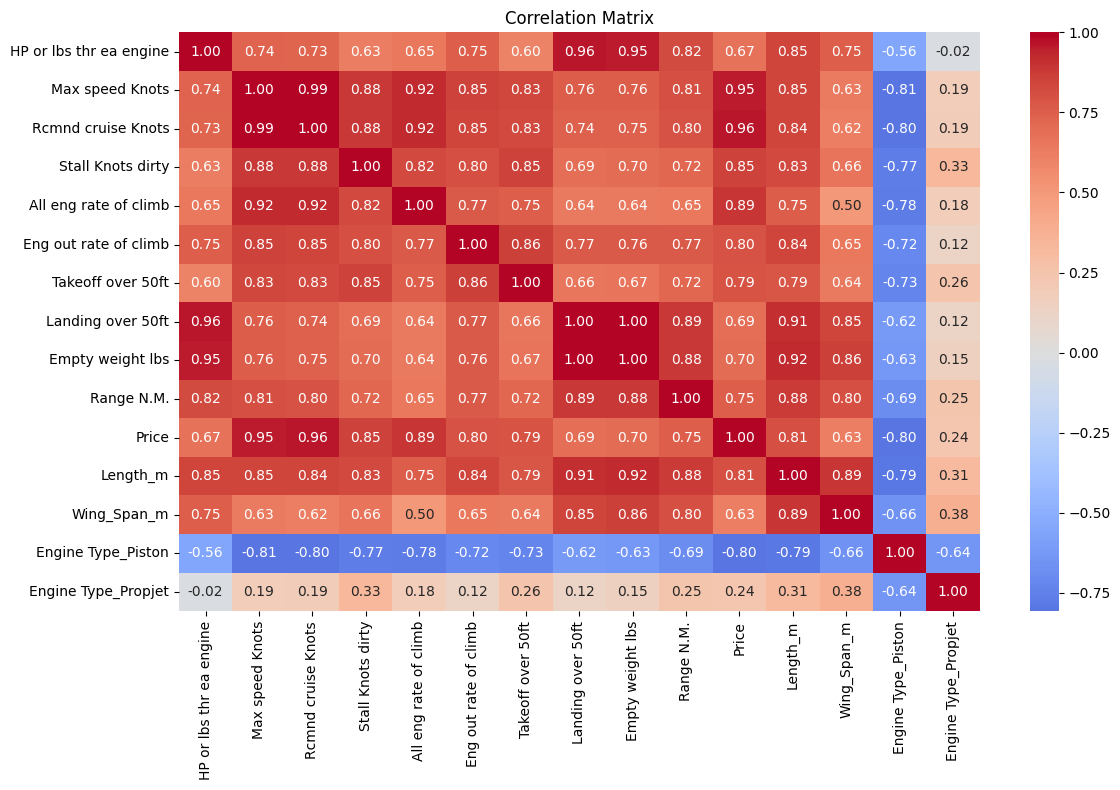

In [425]:
plt.figure(figsize=(12, 8))

corr = df_xgb_imputed.select_dtypes(include='number').corr()

sns.heatmap(
    corr,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0
)

plt.title('Correlation Matrix')
plt.tight_layout()
plt.show()

In [426]:
corr = df_xgb_imputed.select_dtypes(include="number").corr()

print(corr.round(2).to_string())

                         HP or lbs thr ea engine  Max speed Knots  Rcmnd cruise Knots  Stall Knots dirty  All eng rate of climb  Eng out rate of climb  Takeoff over 50ft  Landing over 50ft  Empty weight lbs  Range N.M.  Price  Length_m  Wing_Span_m  Engine Type_Piston  Engine Type_Propjet
HP or lbs thr ea engine                     1.00             0.74                0.73               0.63                   0.65                   0.75               0.60               0.96              0.95        0.82   0.67      0.85         0.75               -0.56                -0.02
Max speed Knots                             0.74             1.00                0.99               0.88                   0.92                   0.85               0.83               0.76              0.76        0.81   0.95      0.85         0.63               -0.81                 0.19
Rcmnd cruise Knots                          0.73             0.99                1.00               0.88                   0.92   

In [427]:
df_xgb_imputed.head()

,HP or lbs thr ea engine,Max speed Knots,Rcmnd cruise Knots,Stall Knots dirty,All eng rate of climb,Eng out rate of climb,Takeoff over 50ft,Landing over 50ft,Empty weight lbs,Range N.M.,Price,Length_m,Wing_Span_m,Engine Type_Piston,Engine Type_Propjet
468,2900.0,456.000000,438.0,91.041283,3180.0,3950.0,2930.000000,15780.0,9925.0,1530.0,4100000.0,14.7574,13.2588,0,0
407,1000.0,280.000000,248.0,88.000000,2635.0,3495.0,2954.447266,14500.0,8737.0,1827.0,2990000.0,18.0848,17.3736,0,1
462,180.0,150.953171,136.0,33.000000,900.0,800.0,600.000000,2300.0,1300.0,525.0,1500000.0,6.9342,9.3980,1,0
207,310.0,243.000000,229.0,71.000000,1650.0,2175.0,1850.000000,5990.0,4184.0,1106.0,2980000.0,10.4648,11.6078,1,0
218,260.0,206.000000,193.0,62.000000,1540.0,1716.0,1673.000000,5200.0,3170.0,676.0,1990000.0,8.8900,11.2014,1,0


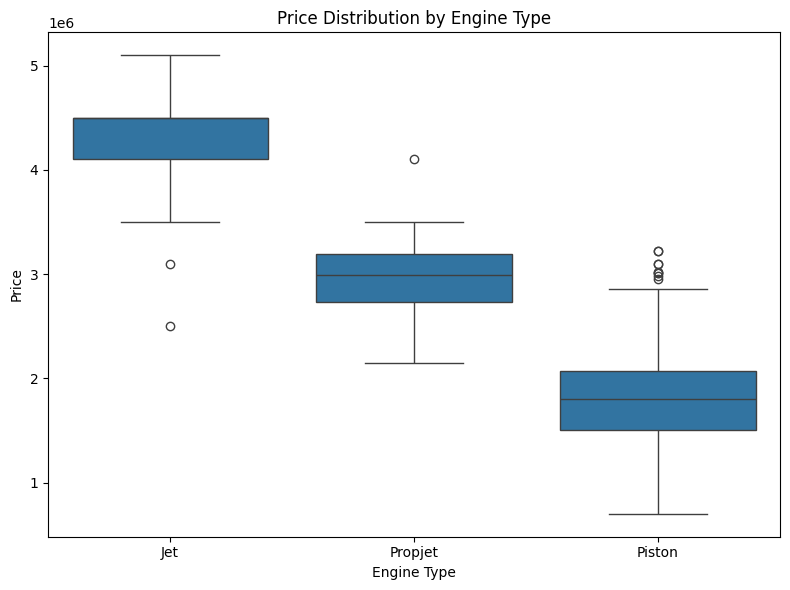

In [428]:
# Recreate Engine Type for visualization
df_plot = df_xgb_imputed.copy()

df_plot['Engine Type'] = np.select(
    [
        df_plot['Engine Type_Piston'] == 1,
        df_plot['Engine Type_Propjet'] == 1
    ],
    [
        'Piston',
        'Propjet'
    ],
    default='Jet'
)

# Price distribution by Engine Type
plt.figure(figsize=(8, 6))

sns.boxplot(
    data=df_plot,
    x='Engine Type',
    y='Price'
)

plt.title('Price Distribution by Engine Type')
plt.xlabel('Engine Type')
plt.ylabel('Price')

plt.tight_layout()
plt.show()

model selection test

In [429]:
#spliting data for da_xgb_imputed


X_train, X_test, y_train, y_test = train_test_split(
    df_xgb_imputed.drop("Price", axis=1),
    df_xgb_imputed["Price"],
    test_size=0.20,
    random_state=42)

In [430]:
#creating dictionary for comparizon

model_comparizon = {}

In [431]:
#evaluating randon forest

rd_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=3,
    random_state=42)

rd_model.fit(X_train, y_train)

y_pred = rd_model.predict(X_test)

mae_rd = mean_absolute_error(y_test, y_pred)
rmse_rd = np.sqrt(mean_squared_error(y_test, y_pred))
r2_rd = r2_score(y_test, y_pred)

model_comparizon["Random Forest"] = {
    "MAE": mae_rd,
    "RMSE": rmse_rd,
    "R2": r2_rd
}


In [432]:
#evaluating gradient boosting

gb_model = GradientBoostingRegressor(
    n_estimators=100,
    max_depth=3,
    random_state=42)

gb_model.fit(X_train, y_train)

y_pred = gb_model.predict(X_test)

mae_gb = mean_absolute_error(y_test, y_pred)
rmse_gb = np.sqrt(mean_squared_error(y_test, y_pred))
r2_gb = r2_score(y_test, y_pred)

model_comparizon["Gradient Boosting"] = {
    "MAE": mae_gb,
    "RMSE": rmse_gb,
    "R2": r2_gb
}
#

In [433]:
#evaluating linear regression

lr_model = LinearRegression()

lr_model.fit(X_train, y_train)

y_pred = lr_model.predict(X_test)

mae_lr = mean_absolute_error(y_test, y_pred)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred))
r2_lr = r2_score(y_test, y_pred)

model_comparizon["Linear Regression"] = {
    "MAE": mae_lr,
    "RMSE": rmse_lr,
    "R2": r2_lr
}

In [434]:
print("Model Comparizon:")
for model_name, metrics in model_comparizon.items():
    print(f"{model_name}:")
    for metric_name, value in metrics.items():
        print(f"  {metric_name}: {value}")

Model Comparizon:
Random Forest:
  MAE: 205355.85054732338
  RMSE: 268029.73902637645
  R2: 0.8701324689628531
Gradient Boosting:
  MAE: 196692.45449832265
  RMSE: 253930.22044140412
  R2: 0.8834362806874089
Linear Regression:
  MAE: 195424.37108629852
  RMSE: 260135.0781499642
  R2: 0.8776701466721775


Gradient boosting presented the best result so it was decided to explore more model

In [435]:
GB_Comparizon = {}

In [436]:
GB_Comparizon["Gradient Boosting"] = {
    "MAE": mae_gb,
    "RMSE": rmse_gb,
    "R2": r2_gb
}

In [437]:
#Evaluating XGBoost model

xgb_model = XGBRegressor(
    n_estimators=100,
    max_depth=5,
    learning_rate=0.05,
    random_state=42)

xgb_model.fit(X_train, y_train)

y_pred = xgb_model.predict(X_test)

mae_xgb = mean_absolute_error(y_test, y_pred)
rmse_xgb = np.sqrt(mean_squared_error(y_test, y_pred))
r2_xgb = r2_score(y_test, y_pred)

GB_Comparizon["XGBoost"] = {
    "MAE": mae_xgb,
    "RMSE": rmse_xgb,
    "R2": r2_xgb
}


In [438]:
#Evaluating LigthGBM model

lgb_model = LGBMRegressor(
    n_estimators=100,
    max_depth=5,
    learning_rate=0.05,
    random_state = 42)

lgb_model.fit(X_train, y_train)

y_pred = lgb_model.predict(X_test)

mae_lgb = mean_absolute_error(y_test, y_pred)
rmse_lgb = np.sqrt(mean_squared_error(y_test, y_pred))
r2_lgb = r2_score(y_test, y_pred)

GB_Comparizon["LightGBM"] = {
    "MAE": mae_lgb,
    "RMSE": rmse_lgb,
    "R2": r2_lgb
}

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000046 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 802
[LightGBM] [Info] Number of data points in the train set: 256, number of used features: 14
[LightGBM] [Info] Start training from score 2447789.062500
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, be

In [439]:
#Evaluating CatBoost model

cat_model = CatBoostRegressor(
    n_estimators=100,
    max_depth=5,
    learning_rate=0.05,
    random_state = 42)

cat_model.fit(X_train, y_train)

y_pred = cat_model.predict(X_test)

mae_cat = mean_absolute_error(y_test, y_pred)
rmse_cat = np.sqrt(mean_squared_error(y_test, y_pred))
r2_cat = r2_score(y_test, y_pred)

GB_Comparizon["CatBoost"] = {
    "MAE": mae_cat,
    "RMSE": rmse_cat,
    "R2": r2_cat
}

0:	learn: 1003121.9954338	total: 4.41ms	remaining: 436ms
1:	learn: 962332.7884589	total: 8.44ms	remaining: 414ms
2:	learn: 925356.3570196	total: 13.3ms	remaining: 431ms
3:	learn: 891315.4383439	total: 17.9ms	remaining: 429ms
4:	learn: 856215.8441131	total: 20.4ms	remaining: 387ms
5:	learn: 825009.1865758	total: 22.8ms	remaining: 357ms
6:	learn: 795301.8290416	total: 25ms	remaining: 332ms
7:	learn: 766307.6392987	total: 27.3ms	remaining: 314ms
8:	learn: 740946.9900390	total: 29.7ms	remaining: 300ms
9:	learn: 713107.0216267	total: 31.9ms	remaining: 287ms
10:	learn: 690098.1224362	total: 34.1ms	remaining: 276ms
11:	learn: 667177.9249405	total: 36.5ms	remaining: 268ms
12:	learn: 645060.1614660	total: 38.6ms	remaining: 259ms
13:	learn: 622017.9599246	total: 41.1ms	remaining: 252ms
14:	learn: 602093.4225323	total: 43.3ms	remaining: 245ms
15:	learn: 583587.0710291	total: 45.5ms	remaining: 239ms
16:	learn: 565781.9439306	total: 47.6ms	remaining: 232ms
17:	learn: 547071.6237610	total: 49.9ms	re

In [440]:
print("GB_Comparizon:")
for model_name, metrics in GB_Comparizon.items():
    print(f"{model_name}:")
    for metric_name, value in metrics.items():
        print(f"  {metric_name}: {value}")

GB_Comparizon:
Gradient Boosting:
  MAE: 196692.45449832265
  RMSE: 253930.22044140412
  R2: 0.8834362806874089
XGBoost:
  MAE: 185502.3826923077
  RMSE: 243419.37013738748
  R2: 0.8928863334370132
LightGBM:
  MAE: 201056.5718354397
  RMSE: 259238.50275689902
  R2: 0.8785119318740972
CatBoost:
  MAE: 203500.25910005101
  RMSE: 256983.4089708077
  R2: 0.8806163675717279


In [441]:
# Feature optimization by Forward Selection using K-Fold Cross-Validation

# ============================================================
# 1. SEPARATE FEATURES AND TARGET
# ============================================================

X = df_xgb_imputed.drop("Price", axis=1)
y = df_xgb_imputed["Price"]


# ============================================================
# 2. TRAIN / TEST SPLIT
#    Test set remains completely untouched
# ============================================================

X_dev, X_test, y_dev, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)


print("Dataset sizes:")
print(f"Total:       {len(X):,}")
print(f"Development: {len(X_dev):,}")
print(f"Test:        {len(X_test):,}")


# ============================================================
# 3. K-FOLD CROSS-VALIDATION
#    Used only for feature selection
# ============================================================

kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


# ============================================================
# 4. XGBOOST MODEL
# ============================================================

xgb_model = XGBRegressor(
    n_estimators=100,
    max_depth=5,
    learning_rate=0.05,
    random_state=42
)


# ============================================================
# 5. FORWARD FEATURE SELECTION
#    Features are selected based on mean CV MAE
# ============================================================

selected_features_XGB = []
results_XGB = []

best_mae_XGB = float("inf")


for feature in X_dev.columns:

    # Add candidate feature
    candidate_features_XGB = selected_features_XGB + [feature]

    fold_mae = []

    # --------------------------------------------------------
    # K-FOLD CROSS-VALIDATION
    # --------------------------------------------------------

    for train_idx, val_idx in kf.split(X_dev):

        X_train_fold = X_dev.iloc[train_idx][candidate_features_XGB]
        X_val_fold = X_dev.iloc[val_idx][candidate_features_XGB]

        y_train_fold = y_dev.iloc[train_idx]
        y_val_fold = y_dev.iloc[val_idx]

        # Create a fresh model for each fold
        model = XGBRegressor(
            n_estimators=100,
            max_depth=5,
            learning_rate=0.05,
            random_state=42
        )

        # Train
        model.fit(
            X_train_fold,
            y_train_fold
        )

        # Predict
        y_pred_fold = model.predict(
            X_val_fold
        )

        # Calculate MAE
        mae_fold = mean_absolute_error(
            y_val_fold,
            y_pred_fold
        )

        fold_mae.append(mae_fold)

    # --------------------------------------------------------
    # MEAN CV MAE
    # --------------------------------------------------------

    mean_mae = np.mean(fold_mae)
    std_mae = np.std(fold_mae)

    # --------------------------------------------------------
    # DECIDE WHETHER FEATURE STAYS
    # --------------------------------------------------------

    if mean_mae <= best_mae_XGB:

        selected_features_XGB.append(feature)
        best_mae_XGB = mean_mae
        status = "Stay"

    else:

        status = "Removed"

    # --------------------------------------------------------
    # STORE RESULTS
    # --------------------------------------------------------

    results_XGB.append({
        "Feature": feature,
        "MAE_CV_Mean": mean_mae,
        "MAE_CV_STD": std_mae,
        "Best_MAE": best_mae_XGB,
        "Result": status,
        "N_Features": len(selected_features_XGB)
    })

    print(
        f"{feature:<30} | "
        f"CV MAE = {mean_mae:,.2f} ± {std_mae:,.2f} | "
        f"{status}"
    )


# ============================================================
# 6. RESULTS
# ============================================================

results_df_XGB = pd.DataFrame(results_XGB)


print("\n" + "=" * 70)
print("FORWARD SELECTION - XGBOOST + 5-FOLD CV")
print("=" * 70)

print("\nSelected features - XGBoost:")
print(selected_features_XGB)

print(f"\nBest CV MAE: {best_mae_XGB:,.2f}")
print(f"Number of selected features: {len(selected_features_XGB)}")

Dataset sizes:
Total:       321
Development: 256
Test:        65
HP or lbs thr ea engine        | CV MAE = 309,596.22 ± 24,585.84 | Stay
Max speed Knots                | CV MAE = 234,524.26 ± 17,306.83 | Stay
Rcmnd cruise Knots             | CV MAE = 221,581.23 ± 12,062.83 | Stay
Stall Knots dirty              | CV MAE = 219,470.79 ± 21,817.24 | Stay
All eng rate of climb          | CV MAE = 219,440.82 ± 14,861.37 | Stay
Eng out rate of climb          | CV MAE = 219,831.57 ± 18,747.65 | Removed
Takeoff over 50ft              | CV MAE = 220,221.46 ± 17,207.09 | Removed
Landing over 50ft              | CV MAE = 211,573.84 ± 16,038.01 | Stay
Empty weight lbs               | CV MAE = 213,093.22 ± 15,893.85 | Removed
Range N.M.                     | CV MAE = 210,775.25 ± 15,204.51 | Stay
Length_m                       | CV MAE = 204,611.53 ± 11,584.71 | Stay
Wing_Span_m                    | CV MAE = 204,434.78 ± 10,525.24 | Stay
Engine Type_Piston             | CV MAE = 205,290.19 ± 12,161.


Selected features:
- HP or lbs thr ea engine
- Max speed Knots
- Rcmnd cruise Knots
- All eng rate of climb
- Eng out rate of climb
- Empty weight lbs
- Range N.M.
- Length_m
- Wing_Span_m
- Engine Type_Piston

Optimal number of features: 10

Feature ranking:
                Feature  Ranking  Selected
HP or lbs thr ea engine        1      True
        Max speed Knots        1      True
     Rcmnd cruise Knots        1      True
  All eng rate of climb        1      True
  Eng out rate of climb        1      True
               Length_m        1      True
             Range N.M.        1      True
       Empty weight lbs        1      True
     Engine Type_Piston        1      True
            Wing_Span_m        1      True
      Stall Knots dirty        2     False
      Landing over 50ft        3     False
      Takeoff over 50ft        4     False
    Engine Type_Propjet        5     False


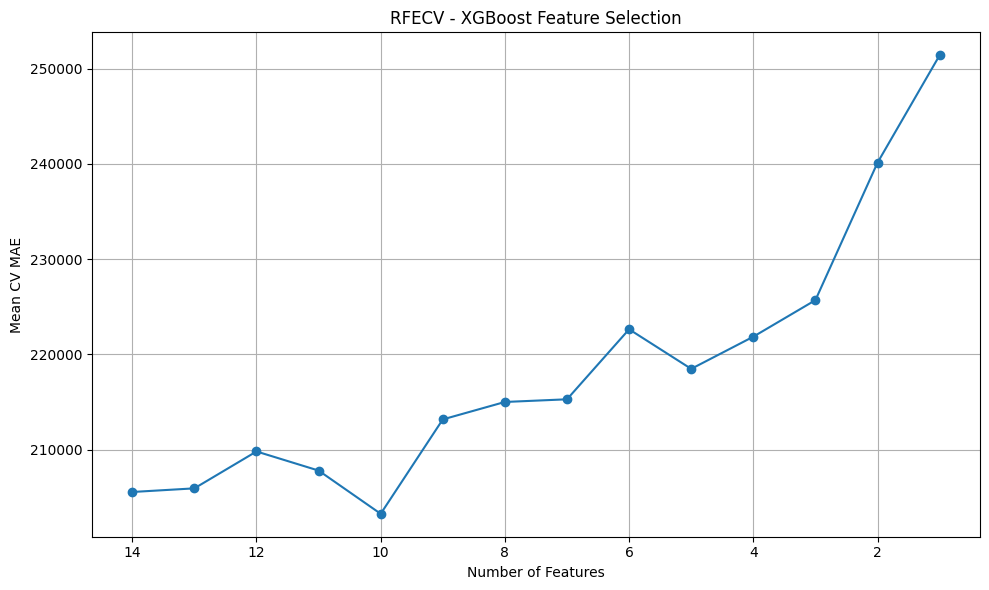


FINAL XGBOOST - RFECV SELECTED FEATURES
Number of features: 10
MAE:  178,974.64
RMSE: 243,928.13
R²:   0.8924
RFECV - BEST CROSS-VALIDATION RESULT
Optimal number of features: 10
Best CV MAE: 203,260.16
CV MAE Std: 12,023.84


In [442]:
#feature optimization by

# ============================================================
# 1. SEPARATE FEATURES AND TARGET
# ============================================================

X = df_xgb_imputed.drop("Price", axis=1)
y = df_xgb_imputed["Price"]


# ============================================================
# 2. TRAIN / TEST SPLIT
#    Test set remains completely untouched
# ============================================================

X_dev, X_test, y_dev, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)


# ============================================================
# 3. XGBOOST MODEL
# ============================================================

xgb_model = XGBRegressor(
    n_estimators=100,
    max_depth=5,
    learning_rate=0.05,
    random_state=42,
    )


# ============================================================
# 4. 5-FOLD CROSS-VALIDATION
# ============================================================

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


# ============================================================
# 5. RFECV
# ============================================================

rfecv = RFECV(
    estimator=xgb_model,
    step=1,
    min_features_to_select=1,
    cv=cv,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)


# Fit RFECV ONLY on development data
rfecv.fit(X_dev, y_dev)


# ============================================================
# 6. SELECTED FEATURES
# ============================================================

selected_features = X_dev.columns[rfecv.support_].tolist()

print("\nSelected features:")
for feature in selected_features:
    print(f"- {feature}")

print(f"\nOptimal number of features: {rfecv.n_features_}")


# ============================================================
# 7. FEATURE RANKING
# ============================================================

feature_ranking = pd.DataFrame({
    "Feature": X_dev.columns,
    "Ranking": rfecv.ranking_,
    "Selected": rfecv.support_
})

feature_ranking = feature_ranking.sort_values(
    by="Ranking"
)

print("\nFeature ranking:")
print(feature_ranking.to_string(index=False))

# ============================================================
# 8. CROSS-VALIDATION PERFORMANCE
# ============================================================

cv_results = pd.DataFrame(rfecv.cv_results_)

mean_mae = -cv_results["mean_test_score"]

n_features = cv_results["n_features"]


plt.figure(figsize=(10, 6))

plt.plot(
    n_features,
    mean_mae,
    marker="o"
)

plt.xlabel("Number of Features")
plt.ylabel("Mean CV MAE")
plt.title("RFECV - XGBoost Feature Selection")

plt.gca().invert_xaxis()

plt.grid(True)
plt.tight_layout()
plt.show()

# ============================================================
# 9. FINAL MODEL WITH SELECTED FEATURES
# ============================================================

final_xgb = XGBRegressor(
    n_estimators=100,
    max_depth=5,
    learning_rate=0.05,
    random_state=42,
    objective="reg:squarederror"
)

final_xgb.fit(
    X_dev[selected_features],
    y_dev
)


# ============================================================
# 10. FINAL TEST EVALUATION
# ============================================================

y_pred = final_xgb.predict(
    X_test[selected_features]
)

mae = mean_absolute_error(
    y_test,
    y_pred
)

rmse = np.sqrt(
    mean_squared_error(y_test, y_pred)
)

r2 = r2_score(
    y_test,
    y_pred
)


print("\n============================================================")
print("FINAL XGBOOST - RFECV SELECTED FEATURES")
print("============================================================")

print(f"Number of features: {len(selected_features)}")
print(f"MAE:  {mae:,.2f}")
print(f"RMSE: {rmse:,.2f}")
print(f"R²:   {r2:.4f}")

# ============================================================
# RFECV - BEST CROSS-VALIDATION RESULT
# ============================================================

cv_results = pd.DataFrame(rfecv.cv_results_)

# Convert negative MAE to positive MAE
cv_results["MAE"] = -cv_results["mean_test_score"]

# Find the best result
best_cv_result = cv_results.loc[
    cv_results["MAE"].idxmin()
]

print("============================================================")
print("RFECV - BEST CROSS-VALIDATION RESULT")
print("============================================================")

print(f"Optimal number of features: {int(best_cv_result['n_features'])}")
print(f"Best CV MAE: {best_cv_result['MAE']:,.2f}")
print(f"CV MAE Std: {best_cv_result['std_test_score']:,.2f}")

In [443]:
# Extract RFECV selected features from the existing model

selected_features = X_dev.columns[rfecv.support_].tolist()

print("Selected features:")
for feature in selected_features:
    print(f"- {feature}")

print(f"\nNumber of selected features: {len(selected_features)}")

Selected features:
- HP or lbs thr ea engine
- Max speed Knots
- Rcmnd cruise Knots
- All eng rate of climb
- Eng out rate of climb
- Empty weight lbs
- Range N.M.
- Length_m
- Wing_Span_m
- Engine Type_Piston

Number of selected features: 10


In [444]:
#filtering data_set

df_final = df_xgb_imputed[selected_features + ['Price']]

In [445]:
# ============================================================
# 1. TRAIN / VALIDATION / TEST SPLIT
# ============================================================

X = df_final.drop("Price", axis=1)
y = df_final["Price"]

# Final test set: created once and never used during optimization
X_dev, X_test, y_dev, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Training / validation split
X_train, X_val, y_train, y_val = train_test_split(
    X_dev,
    y_dev,
    test_size=0.20,
    random_state=42
)


# ============================================================
# 2. DEFINE 7 HYPERPARAMETER LEVELS
# ============================================================

factor_levels = {

    "n_estimators": [
        100, 200, 300, 400, 500, 650, 800
    ],

    "max_depth": [
        2, 3, 4, 5, 6, 7, 8
    ],

    "learning_rate": [
        0.01, 0.03, 0.05, 0.08, 0.10, 0.13, 0.15
    ],

    "subsample": [
        0.60, 0.65, 0.70, 0.75, 0.80, 0.90, 1.00
    ],

    "colsample_bytree": [
        0.60, 0.65, 0.70, 0.75, 0.80, 0.90, 1.00
    ],

    "min_child_weight": [
        1, 2, 3, 4, 5, 6, 7
    ],

    "gamma": [
        0.00, 0.03, 0.05, 0.08, 0.10, 0.15, 0.20
    ],

    "reg_alpha": [
        0.00, 0.01, 0.025, 0.05, 0.075, 0.10, 0.15
    ],

    "reg_lambda": [
        0.5, 1.0, 1.5, 2.5, 3.5, 4.0, 5.0
    ]
}


factor_names = list(factor_levels.keys())


# ============================================================
# 3. CREATE 7-LEVEL FRACTIONAL DOE
# ============================================================

# A full factorial would require:
#
# 7^9 = 40,353,607 experiments
#
# Instead, use a fractional design with 49 runs.
#
# Two base factors are varied across all 7 x 7 combinations.
# The remaining factors are generated deterministically.

base_design = list(
    itertools.product(range(7), repeat=2)
)

design = []

for a, b in base_design:

    row = [

        a,

        b,

        (a + b) % 7,

        (a + 2*b) % 7,

        (2*a + b) % 7,

        (a + 3*b) % 7,

        (2*a + 3*b) % 7,

        (3*a + b) % 7,

        (3*a + 2*b) % 7
    ]

    design.append(row)


design_df = pd.DataFrame(
    design,
    columns=factor_names
)


# ============================================================
# 4. CONVERT DOE LEVELS TO REAL HYPERPARAMETERS
# ============================================================

for factor in factor_names:

    levels = factor_levels[factor]

    design_df[factor] = design_df[factor].map({
        0: levels[0],
        1: levels[1],
        2: levels[2],
        3: levels[3],
        4: levels[4],
        5: levels[5],
        6: levels[6]
    })


# ============================================================
# 5. DISPLAY DOE INFORMATION
# ============================================================

print("=" * 70)
print("7-LEVEL DOE")
print("=" * 70)

print(f"Number of factors     : {len(factor_names)}")
print(f"Number of levels      : 7")
print(f"Number of experiments : {len(design_df)}")

print("\nHyperparameter levels:")

for factor, levels in factor_levels.items():

    print(f"\n{factor}")

    for level, value in enumerate(levels):

        print(
            f"  Level {level + 1}: {value}"
        )


# ============================================================
# 6. RUN DOE EXPERIMENTS
# ============================================================

results = []

for i, row in design_df.iterrows():

    params = row.to_dict()

    # Ensure integer hyperparameters are integers
    params["n_estimators"] = int(
        params["n_estimators"]
    )

    params["max_depth"] = int(
        params["max_depth"]
    )

    params["min_child_weight"] = int(
        params["min_child_weight"]
    )

    model = XGBRegressor(
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1,
        **params
    )

    # --------------------------------------------------------
    # Train ONLY on training data
    # --------------------------------------------------------

    model.fit(
        X_train,
        y_train
    )

    # --------------------------------------------------------
    # Evaluate ONLY on validation data
    # --------------------------------------------------------

    y_val_pred = model.predict(
        X_val
    )

    mae = mean_absolute_error(
        y_val,
        y_val_pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_val,
            y_val_pred
        )
    )

    r2 = r2_score(
        y_val,
        y_val_pred
    )

    results.append({

        "Run": i + 1,

        **params,

        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

    print(
        f"Run {i + 1:02d}/{len(design_df)} | "
        f"MAE: {mae:.4f} | "
        f"RMSE: {rmse:.4f} | "
        f"R²: {r2:.4f}"
    )


# ============================================================
# 7. RESULTS DATAFRAME
# ============================================================

results_df = pd.DataFrame(
    results
)

results_df = results_df.sort_values(
    by="MAE",
    ascending=True
).reset_index(
    drop=True
)


# ============================================================
# 8. BEST DOE RESULT
# ============================================================

best_row = results_df.iloc[0]

best_params = {

    factor: best_row[factor]

    for factor in factor_names
}


# Ensure correct parameter types
best_params["n_estimators"] = int(
    best_params["n_estimators"]
)

best_params["max_depth"] = int(
    best_params["max_depth"]
)

best_params["min_child_weight"] = int(
    best_params["min_child_weight"]
)


print("\n" + "=" * 70)
print("BEST DOE RESULT")
print("=" * 70)

for parameter, value in best_params.items():

    print(
        f"{parameter:<20}: {value}"
    )

print("\nValidation Performance:")

print(
    f"MAE  : {best_row['MAE']:.4f}"
)

print(
    f"RMSE : {best_row['RMSE']:.4f}"
)

print(
    f"R²   : {best_row['R2']:.4f}"
)


# ============================================================
# 9. HYPERPARAMETER EFFECTS
# ============================================================

print("\n" + "=" * 70)
print("HYPERPARAMETER EFFECTS")
print("=" * 70)

for factor in factor_names:

    effect = (
        results_df
        .groupby(factor)["MAE"]
        .mean()
        .sort_index()
    )

    print(f"\n{factor}")
    print(effect)


# ============================================================
# 10. FINAL MODEL
# ============================================================

# Combine training + validation data
# ONLY AFTER hyperparameter optimization

X_final_train = pd.concat(
    [X_train, X_val],
    axis=0
)

y_final_train = pd.concat(
    [y_train, y_val],
    axis=0
)


final_model = XGBRegressor(
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1,
    **best_params
)

final_model.fit(
    X_final_train,
    y_final_train
)


# ============================================================
# 11. FINAL TEST EVALUATION
# ============================================================

# X_test is used ONLY here

y_test_pred = final_model.predict(
    X_test
)

test_mae = mean_absolute_error(
    y_test,
    y_test_pred
)

test_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        y_test_pred
    )
)

test_r2 = r2_score(
    y_test,
    y_test_pred
)


print("\n" + "=" * 70)
print("FINAL TEST PERFORMANCE")
print("=" * 70)

print(
    f"MAE  : {test_mae:.4f}"
)

print(
    f"RMSE : {test_rmse:.4f}"
)

print(
    f"R²   : {test_r2:.4f}"
)


# ============================================================
# 12. SAVE FINAL MODEL
# ============================================================

final_model.save_model(
    "xgboost_best_model.json"
)


# ============================================================
# 13. SAVE DOE RESULTS
# ============================================================

results_df.to_csv(
    "xgboost_doe7_results.csv",
    index=False
)


print("\n" + "=" * 70)
print("FILES SAVED")
print("=" * 70)

print(
    "xgboost_best_model.json"
)

print(
    "xgboost_doe7_results.csv"
)

7-LEVEL DOE
Number of factors     : 9
Number of levels      : 7
Number of experiments : 49

Hyperparameter levels:

n_estimators
  Level 1: 100
  Level 2: 200
  Level 3: 300
  Level 4: 400
  Level 5: 500
  Level 6: 650
  Level 7: 800

max_depth
  Level 1: 2
  Level 2: 3
  Level 3: 4
  Level 4: 5
  Level 5: 6
  Level 6: 7
  Level 7: 8

learning_rate
  Level 1: 0.01
  Level 2: 0.03
  Level 3: 0.05
  Level 4: 0.08
  Level 5: 0.1
  Level 6: 0.13
  Level 7: 0.15

subsample
  Level 1: 0.6
  Level 2: 0.65
  Level 3: 0.7
  Level 4: 0.75
  Level 5: 0.8
  Level 6: 0.9
  Level 7: 1.0

colsample_bytree
  Level 1: 0.6
  Level 2: 0.65
  Level 3: 0.7
  Level 4: 0.75
  Level 5: 0.8
  Level 6: 0.9
  Level 7: 1.0

min_child_weight
  Level 1: 1
  Level 2: 2
  Level 3: 3
  Level 4: 4
  Level 5: 5
  Level 6: 6
  Level 7: 7

gamma
  Level 1: 0.0
  Level 2: 0.03
  Level 3: 0.05
  Level 4: 0.08
  Level 5: 0.1
  Level 6: 0.15
  Level 7: 0.2

reg_alpha
  Level 1: 0.0
  Level 2: 0.01
  Level 3: 0.025
  Level 4: 

In [446]:
#k-fold validation


kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_model = XGBRegressor(
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1,
    **best_params
)

scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2"
}

cv_results = cross_validate(
    cv_model,
    X_dev,
    y_dev,
    cv=kf,
    scoring=scoring,
    return_train_score=False,
    n_jobs=-1
)

cv_mae = -cv_results["test_MAE"]
cv_rmse = -cv_results["test_RMSE"]
cv_r2 = cv_results["test_R2"]

print("=" * 70)
print("5-FOLD CROSS-VALIDATION")
print("=" * 70)

for i in range(5):

    print(
        f"Fold {i + 1}: "
        f"MAE = {cv_mae[i]:.4f} | "
        f"RMSE = {cv_rmse[i]:.4f} | "
        f"R² = {cv_r2[i]:.4f}"
    )

5-FOLD CROSS-VALIDATION
Fold 1: MAE = 183092.9976 | RMSE = 242953.2197 | R² = 0.9343
Fold 2: MAE = 182689.3407 | RMSE = 265357.9078 | R² = 0.9256
Fold 3: MAE = 213179.8775 | RMSE = 288733.4780 | R² = 0.9348
Fold 4: MAE = 218558.6838 | RMSE = 289983.8677 | R² = 0.9074
Fold 5: MAE = 209254.1164 | RMSE = 315368.2400 | R² = 0.9241


In [447]:
# ============================================================
# 2. CROSS-VALIDATION SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("CROSS-VALIDATION SUMMARY")
print("=" * 70)

print(
    f"MAE  : {cv_mae.mean():.4f} ± {cv_mae.std():.4f}"
)

print(
    f"RMSE : {cv_rmse.mean():.4f} ± {cv_rmse.std():.4f}"
)

print(
    f"R²   : {cv_r2.mean():.4f} ± {cv_r2.std():.4f}"
)


CROSS-VALIDATION SUMMARY
MAE  : 201355.0032 ± 15362.9299
RMSE : 280479.3426 ± 24546.1590
R²   : 0.9252 ± 0.0099


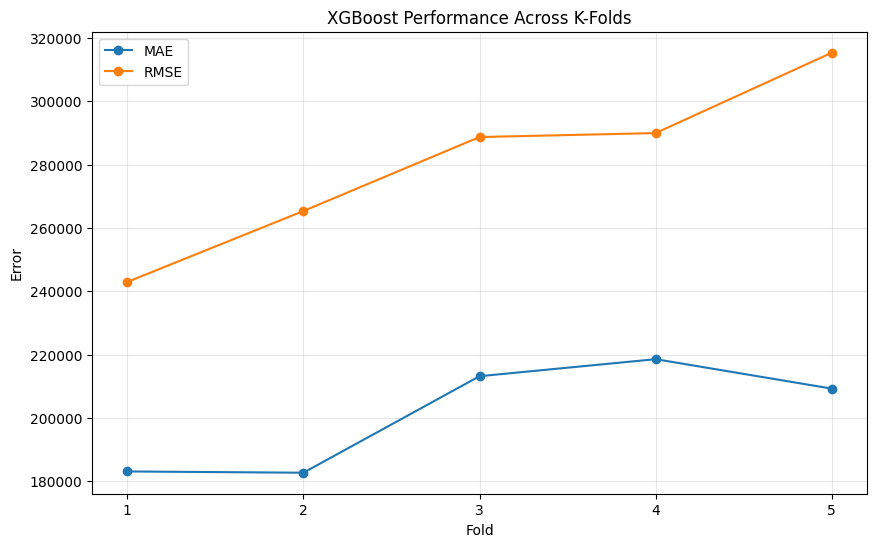

In [448]:
# ============================================================
# 3. K-FOLD PERFORMANCE PLOT
# ============================================================

import matplotlib.pyplot as plt

folds = np.arange(1, 6)

plt.figure(figsize=(10, 6))

plt.plot(
    folds,
    cv_mae,
    marker="o",
    label="MAE"
)

plt.plot(
    folds,
    cv_rmse,
    marker="o",
    label="RMSE"
)

plt.xlabel("Fold")
plt.ylabel("Error")
plt.title("XGBoost Performance Across K-Folds")
plt.xticks(folds)
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

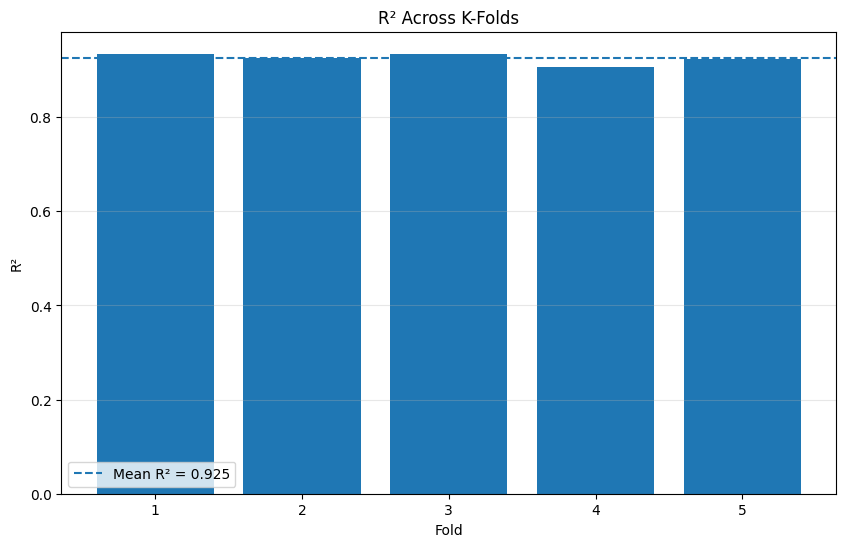

In [449]:
# ============================================================
# 4. R² ACROSS FOLDS
# ============================================================

plt.figure(figsize=(10, 6))

plt.bar(
    folds,
    cv_r2
)

plt.axhline(
    cv_r2.mean(),
    linestyle="--",
    label=f"Mean R² = {cv_r2.mean():.3f}"
)

plt.xlabel("Fold")
plt.ylabel("R²")
plt.title("R² Across K-Folds")
plt.xticks(folds)
plt.legend()
plt.grid(True, axis="y", alpha=0.3)

plt.show()

In [450]:
df_test.columns


Index(['Model Name', 'Engine Type', 'HP or lbs thr ea engine',
       'Max speed Knots', 'Rcmnd cruise Knots', 'Stall Knots dirty',
       'Fuel gal/lbs', 'All eng rate of climb', 'Eng out rate of climb',
       'Takeoff over 50ft', 'Landing over 50ft', 'Empty weight lbs',
       'Range N.M.', 'Price', 'Length_m', 'Wing_Span_m'],
      dtype='object')

In [451]:
# ============================================================
# ENCODING ENGINE TYPE
# ============================================================

# Standardize Engine Type
df_test['Engine Type'] = (
    df_test['Engine Type']
    .astype(str)
    .str.strip()
    .str.lower()
    .replace({
        'piston': 'Piston',
        'jet': 'Jet',
        'propjet': 'Propjet'
    })
)

# One-Hot Encoding
df_test = pd.get_dummies(
    df_test,
    columns=['Engine Type'],
    drop_first=True,
    dtype=int
)

# Check result
print(df_test[['Engine Type_Piston', 'Engine Type_Propjet']].value_counts())

Engine Type_Piston  Engine Type_Propjet
1                   0                      58
0                   0                      16
                    1                       9
Name: count, dtype: int64


In [452]:
df_test.columns

Index(['Model Name', 'HP or lbs thr ea engine', 'Max speed Knots',
       'Rcmnd cruise Knots', 'Stall Knots dirty', 'Fuel gal/lbs',
       'All eng rate of climb', 'Eng out rate of climb', 'Takeoff over 50ft',
       'Landing over 50ft', 'Empty weight lbs', 'Range N.M.', 'Price',
       'Length_m', 'Wing_Span_m', 'Engine Type_Piston', 'Engine Type_Propjet'],
      dtype='object')

In [453]:
df_test.dtypes

,0
Model Name,object
HP or lbs thr ea engine,float64
Max speed Knots,float64
Rcmnd cruise Knots,float64
Stall Knots dirty,float64
Fuel gal/lbs,int64
All eng rate of climb,float64
Eng out rate of climb,float64
Takeoff over 50ft,float64
Landing over 50ft,float64


In [454]:
df_test = df_test.drop(columns=['Model Name'])

In [458]:
df_test = df_test.dropna()

In [459]:
# Separate test features (X) and target (y)

X_test = df_test.drop(columns=['Price']).copy()
y_test = df_test['Price'].copy()

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_test shape: (66, 15)
y_test shape: (66,)


In [460]:
df_test.head()

,HP or lbs thr ea engine,Max speed Knots,Rcmnd cruise Knots,Stall Knots dirty,Fuel gal/lbs,All eng rate of climb,Eng out rate of climb,Takeoff over 50ft,Landing over 50ft,Empty weight lbs,Range N.M.,Price,Length_m,Wing_Span_m,Engine Type_Piston,Engine Type_Propjet
338,160.0,96.0,95.0,44.0,43,740.0,2160.0,1345.0,2220.0,1632.0,440.0,1500000.0,8.1280,10.9220,1,0
129,225.0,170.0,161.0,52.0,50,960.0,1235.0,1282.0,3000.0,1745.0,568.0,1840000.0,7.7724,10.0076,1,0
381,4250.0,512.0,457.0,90.0,8980,3500.0,6400.0,4850.0,27337.0,15400.0,1630.0,4200000.0,17.1450,16.3068,0,0
221,260.0,209.0,194.0,65.0,102,1690.0,1545.0,1900.0,5100.0,3063.0,687.0,2110000.0,8.9662,11.4046,1,0
326,175.0,123.0,118.0,56.0,52,790.0,1450.0,1170.0,2450.0,1325.0,589.0,1450000.0,7.6200,10.9728,1,0


In [461]:
# ============================================================
# 5. FINAL TEST EVALUATION
# ============================================================

# Keep exactly the features used during model training
X_test = X_test.reindex(
    columns=final_model.feature_names_in_,
    fill_value=0
)

# Generate predictions

y_test_pred = final_model.predict(X_test)

test_mae = mean_absolute_error(
    y_test,
    y_test_pred
)

test_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        y_test_pred
    )
)

test_r2 = r2_score(
    y_test,
    y_test_pred
)

print("=" * 70)
print("FINAL TEST PERFORMANCE")
print("=" * 70)

print(f"MAE  : {test_mae:.4f}")
print(f"RMSE : {test_rmse:.4f}")
print(f"R²   : {test_r2:.4f}")

FINAL TEST PERFORMANCE
MAE  : 157891.4972
RMSE : 215083.0272
R²   : 0.9576


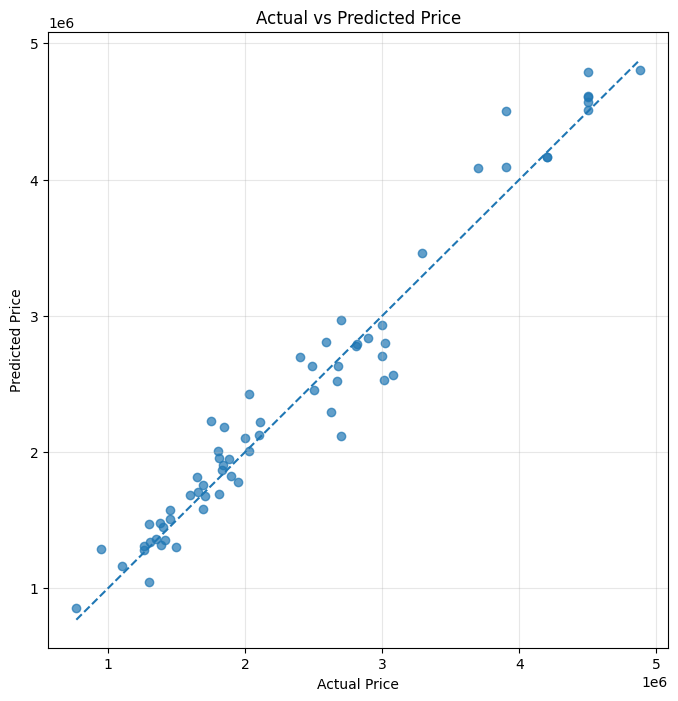

In [462]:
# ============================================================
# 6. ACTUAL VS PREDICTED
# ============================================================

plt.figure(figsize=(8, 8))

plt.scatter(
    y_test,
    y_test_pred,
    alpha=0.7
)

min_value = min(
    y_test.min(),
    y_test_pred.min()
)

max_value = max(
    y_test.max(),
    y_test_pred.max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Price")

plt.grid(True, alpha=0.3)

plt.show()

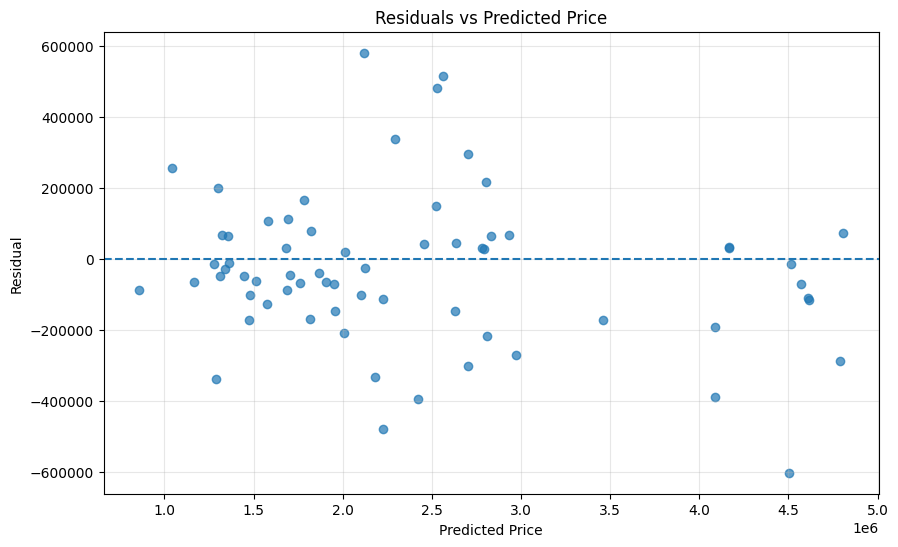

In [463]:
# ============================================================
# 7. RESIDUAL ANALYSIS
# ============================================================

residuals = y_test - y_test_pred

plt.figure(figsize=(10, 6))

plt.scatter(
    y_test_pred,
    residuals,
    alpha=0.7
)

plt.axhline(
    0,
    linestyle="--"
)

plt.xlabel("Predicted Price")
plt.ylabel("Residual")
plt.title("Residuals vs Predicted Price")

plt.grid(True, alpha=0.3)

plt.show()

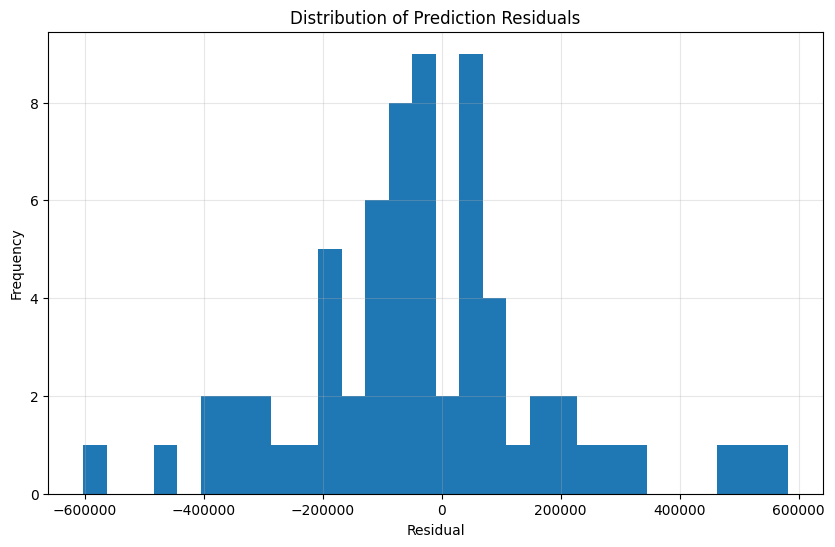

In [464]:
# ============================================================
# 8. RESIDUAL DISTRIBUTION
# ============================================================

plt.figure(figsize=(10, 6))

plt.hist(
    residuals,
    bins=30
)

plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.title("Distribution of Prediction Residuals")

plt.grid(True, alpha=0.3)

plt.show()

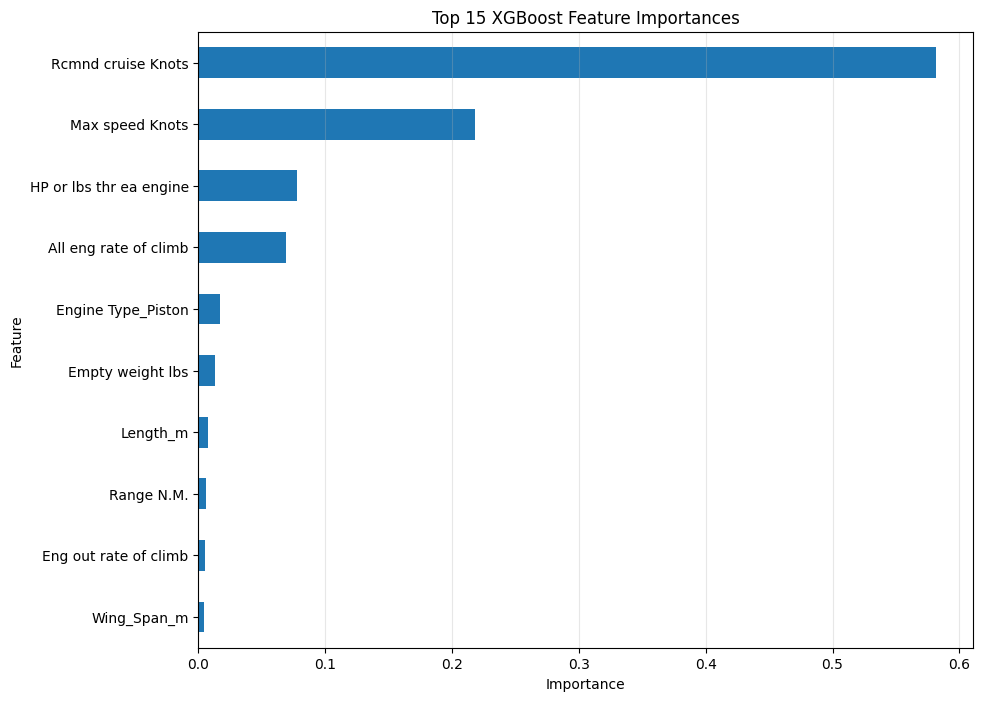

In [465]:
# ============================================================
# 9. FEATURE IMPORTANCE
# ============================================================

importance = pd.Series(
    final_model.feature_importances_,
    index=X.columns
).sort_values(
    ascending=False
)

plt.figure(figsize=(10, 8))

importance.head(15).sort_values().plot(
    kind="barh"
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 15 XGBoost Feature Importances")

plt.grid(True, axis="x", alpha=0.3)

plt.show()

In [466]:
# ============================================================
# 10. MODEL PERFORMANCE SUMMARY
# ============================================================

performance_summary = pd.DataFrame({
    "Dataset": [
        "DOE Validation",
        "5-Fold CV Mean",
        "Final Test"
    ],

    "MAE": [
        best_row["MAE"],
        cv_mae.mean(),
        test_mae
    ],

    "RMSE": [
        best_row["RMSE"],
        cv_rmse.mean(),
        test_rmse
    ],

    "R2": [
        best_row["R2"],
        cv_r2.mean(),
        test_r2
    ]
})

print("=" * 70)
print("MODEL PERFORMANCE SUMMARY")
print("=" * 70)

print(
    performance_summary.to_string(
        index=False
    )
)

MODEL PERFORMANCE SUMMARY
       Dataset           MAE          RMSE       R2
DOE Validation 183092.997596 242953.219711 0.934291
5-Fold CV Mean 201355.003196 280479.342632 0.925246
    Final Test 157891.497159 215083.027162 0.957565
